# 03. LCMAN-lite в multi-rate постановке

## Исследовательский вопрос
Можно ли, опираясь на инженерный baseline из `02_multimodal_pipeline_baseline.ipynb`, получить более сильную и при этом лёгкую мультимодальную модель для предсбойного контура (логи + KPI) в multi-rate логике?

Цель `03` — не построить «зоопарк» моделей, а методически усилить контур `02`: сохранить компактный стек (PyTorch, embedding-ветка логов, KPI 1D-CNN, gated fusion, group-aware protocol), добавить dual-target обучение и coverage-aware оценку.


## 0. Постановка и связь `01 -> 02 -> 03`

Логика этапов в ВКР теперь следующая:
- `01_eda.ipynb` фиксирует ограничения данных: асимметрия покрытий, риск shortcut через `kpi_available`, требования к anti-leakage протоколу;
- `02_multimodal_pipeline_baseline.ipynb` задаёт инженерный контур: multi-rate признаки (`macro=5min`, `micro=10s/30s`), dual-target (`y_warning`, `y_risk`), балансировку train и smoke-сравнение;
- `03` усиливает именно модельный слой этого же контура, не меняя базовую методологию.

Критерий готовности `03`:
1. Контракт данных совместим с новой multi-rate/dual-target схемой и явно контролирует missingness.
2. Модель остаётся lightweight (embedding logs + KPI 1D-CNN + gated fusion), но расширяется до multi-rate входов.
3. Обучение включает modality dropout и вторичную цель `y_risk` при основной цели `y_warning`.
4. Сравнение включает минимум `availability-only`, `log-only`, `kpi-only`, `fused baseline`, `LCMAN-lite`.
5. Основной вывод формулируется через `PR-AUC(y_warning)` и обязательные срезы `kpi_available=1` и `has_both_modalities=1`, с отдельным отчётом по `y_risk`.


In [1]:
import os
import requests
from huggingface_hub import login, whoami

# Стабилизация загрузок HF (часто устраняет зависания на 70-90%)
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "240")
os.environ.setdefault("HF_HUB_ENABLE_HF_TRANSFER", "0")


def resolve_hf_token() -> tuple[str | None, str]:
    env_priority = ["HF_TOKEN", "HUGGINGFACE_HUB_TOKEN", "HUGGINGFACE_TOKEN"]
    for env_name in env_priority:
        token = os.getenv(env_name)
        if isinstance(token, str) and token.strip().startswith("hf_") and len(token.strip()) > 20:
            return token.strip(), f"env:{env_name}"

    cached_token = None
    try:
        from huggingface_hub import get_token
        cached_token = get_token()
    except Exception:
        try:
            from huggingface_hub import HfFolder  # legacy API
            cached_token = HfFolder.get_token()
        except Exception:
            cached_token = None

    if isinstance(cached_token, str) and cached_token.strip().startswith("hf_") and len(cached_token.strip()) > 20:
        return cached_token.strip(), "huggingface_hub cache"

    return None, "missing"


HF_TOKEN, HF_TOKEN_SOURCE = resolve_hf_token()
print(f"HF token найден: {HF_TOKEN is not None} | source: {HF_TOKEN_SOURCE}")

try:
    resp = requests.get("https://huggingface.co", timeout=8)
    print(f"Доступ к huggingface.co: HTTP {resp.status_code}")
except Exception as exc:
    print(f"Доступ к huggingface.co: ошибка сети ({exc})")

if HF_TOKEN is not None:
    try:
        login(token=HF_TOKEN, add_to_git_credential=False)
    except TypeError:
        login(HF_TOKEN)
    except Exception as exc:
        print(f"login() завершился с предупреждением: {exc}")

try:
    user_info = whoami(token=HF_TOKEN) if HF_TOKEN is not None else whoami()
    print(f"Авторизация Hugging Face: OK | user={user_info.get('name', 'unknown')}")
except Exception as exc:
    print(f"Авторизация Hugging Face: не подтверждена ({exc})")

print("Gemma будет загружаться через явный token в SentenceTransformer (если токен найден).")

HF token найден: True | source: huggingface_hub cache
Доступ к huggingface.co: HTTP 200
Авторизация Hugging Face: OK | user=Vasileck
Gemma будет загружаться через явный token в SentenceTransformer (если токен найден).


In [2]:
from __future__ import annotations

import hashlib
import json
import os
import random
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

SEED = 42


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
sns.set_theme(style="whitegrid")
pd.options.display.max_colwidth = 180

ROOT = Path.cwd()
DATA_CANDIDATES = [
    ROOT / "outputs" / "final_demo" / "multirate_windows_reference.csv",
    ROOT / "outputs" / "final_demo" / "scored_windows_multirate.csv",
    ROOT / "outputs" / "final_demo" / "aligned_multirate_windows.csv",
    ROOT / "outputs" / "final_demo" / "scored_windows_reference.csv",  # технический fallback
]
BASELINE_PATH = ROOT / "outputs" / "final_demo" / "baseline_summary_metrics.json"
OUT_DIR = ROOT / "outputs" / "lcman"
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_HF_ENCODER = True

print(f"Device: {DEVICE} | USE_HF_ENCODER={USE_HF_ENCODER}")


Device: cpu | USE_HF_ENCODER=True


In [3]:
def resolve_data_path(candidates: list[Path]) -> tuple[Path, str]:
    existing = [p for p in candidates if p.exists()]
    if not existing:
        searched = [str(p.relative_to(ROOT)) for p in candidates]
        raise FileNotFoundError(f"Не найден data contract файл. Проверены пути: {searched}")

    preferred = [p for p in existing if p.name != "scored_windows_reference.csv"]
    if preferred:
        return preferred[0], "primary"
    return existing[0], "legacy_fallback"


def pick_first_series(frame: pd.DataFrame, candidates: list[str], default: float | str = 0.0) -> pd.Series:
    for col in candidates:
        if col in frame.columns:
            return frame[col]
    return pd.Series(default, index=frame.index)


def harmonize_contract(raw: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    df = raw.copy()
    notes: list[str] = []

    if "run_id" not in df.columns:
        raise ValueError("В контракте отсутствует колонка run_id")
    df["run_id"] = df["run_id"].astype(str)

    if "fail_start" in df.columns:
        df["fail_start"] = pd.to_datetime(df["fail_start"], utc=True, errors="coerce")
    else:
        df["fail_start"] = pd.NaT
        notes.append("fail_start отсутствовал, заполнен после расчёта window_ts")

    if "window_ts" in df.columns:
        df["window_ts"] = pd.to_datetime(df["window_ts"], utc=True, errors="coerce")
    elif "micro_ts" in df.columns:
        df["window_ts"] = pd.to_datetime(df["micro_ts"], utc=True, errors="coerce")
        notes.append("window_ts получен из micro_ts")
    elif {"fail_start", "relative_min"}.issubset(df.columns):
        rel_min = pd.to_numeric(df["relative_min"], errors="coerce")
        df["window_ts"] = pd.to_datetime(df["fail_start"], utc=True, errors="coerce") - pd.to_timedelta(rel_min, unit="m")
        notes.append("window_ts восстановлен из fail_start + relative_min")
    elif {"fail_start", "relative_sec"}.issubset(df.columns):
        rel_sec = pd.to_numeric(df["relative_sec"], errors="coerce")
        df["window_ts"] = pd.to_datetime(df["fail_start"], utc=True, errors="coerce") - pd.to_timedelta(rel_sec, unit="s")
        notes.append("window_ts восстановлен из fail_start + relative_sec")
    else:
        df["window_ts"] = pd.to_datetime(df["fail_start"], utc=True, errors="coerce")
        notes.append("window_ts заполнен fail_start (технический fallback)")

    if df["fail_start"].isna().all():
        df["fail_start"] = df["window_ts"]

    if "group_id" not in df.columns:
        for candidate in ["episode_id", "overlap_group"]:
            if candidate in df.columns:
                df["group_id"] = df[candidate].astype(str)
                notes.append(f"group_id получен из {candidate}")
                break
    if "group_id" not in df.columns:
        df["group_id"] = df["run_id"].astype(str)
        notes.append("group_id заполнен run_id (fallback без overlap-групп)")

    if "state" in df.columns:
        state_series = df["state"].astype(str).str.lower()
    elif "true_state" in df.columns:
        state_series = df["true_state"].astype(str).str.lower()
        notes.append("state получен из true_state")
    else:
        state_series = pd.Series("normal", index=df.index)
        notes.append("state отсутствовал, заполнен как normal")

    state_series = state_series.replace({"anomaly": "risk", "critical": "risk"})

    if "y_warning" in df.columns:
        y_warning = pd.to_numeric(df["y_warning"], errors="coerce").fillna(0).astype(int)
    else:
        y_warning = state_series.eq("warning").astype(int)
        notes.append("y_warning восстановлен из state")

    if "y_risk" in df.columns:
        y_risk = pd.to_numeric(df["y_risk"], errors="coerce").fillna(0).astype(int)
    else:
        y_risk = state_series.isin(["risk", "anomaly"]).astype(int)
        notes.append("y_risk восстановлен из state")

    df["y_warning"] = y_warning
    df["y_risk"] = y_risk
    df["state"] = np.select(
        [df["y_risk"].eq(1), df["y_warning"].eq(1)],
        ["risk", "warning"],
        default="normal",
    )

    df["log_text"] = pick_first_series(df, ["log_text"], default="__NO_LOG__").fillna("__NO_LOG__").astype(str)

    df["log_count"] = pd.to_numeric(pick_first_series(df, ["log_count", "micro_log_count", "macro_log_count"], 0.0), errors="coerce").fillna(0.0)
    df["unique_templates"] = pd.to_numeric(pick_first_series(df, ["unique_templates", "micro_unique_templates", "macro_unique_templates"], 0.0), errors="coerce").fillna(0.0)
    df["error_count"] = pd.to_numeric(pick_first_series(df, ["error_count", "micro_error_count", "macro_error_count"], 0.0), errors="coerce").fillna(0.0)

    if "log_available" in df.columns:
        df["log_available"] = pd.to_numeric(df["log_available"], errors="coerce").fillna(0).astype(int)
    else:
        df["log_available"] = df["log_count"].gt(0).astype(int)

    series_avail_cols = [
        c
        for c in df.columns
        if c.endswith("__avail") and "__family_pool" not in c
    ]

    if "kpi_series_available" in df.columns:
        df["kpi_series_available"] = pd.to_numeric(df["kpi_series_available"], errors="coerce").fillna(0).astype(int)
    elif series_avail_cols:
        avail_block = df[series_avail_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        df["kpi_series_available"] = avail_block.gt(0).sum(axis=1).astype(int)
        notes.append("kpi_series_available восстановлен по series__avail")
    else:
        df["kpi_series_available"] = 0

    if "kpi_available" in df.columns:
        df["kpi_available"] = pd.to_numeric(df["kpi_available"], errors="coerce").fillna(0).astype(int)
    else:
        df["kpi_available"] = df["kpi_series_available"].gt(0).astype(int)
        notes.append("kpi_available восстановлен из kpi_series_available")

    macro_map = {
        "macro_log_count": ["macro_log_count", "log_count"],
        "macro_unique_templates": ["macro_unique_templates", "unique_templates"],
        "macro_error_count": ["macro_error_count", "error_count"],
    }
    for out_col, cand in macro_map.items():
        df[out_col] = pd.to_numeric(pick_first_series(df, cand, 0.0), errors="coerce").fillna(0.0)

    micro_map = {
        "micro_log_count": ["micro_log_count", "log_count_roll60", "log_count"],
        "micro_unique_templates": ["micro_unique_templates", "unique_templates_roll60", "unique_templates"],
        "micro_error_count": ["micro_error_count", "error_count_roll60", "error_count"],
    }
    for out_col, cand in micro_map.items():
        df[out_col] = pd.to_numeric(pick_first_series(df, cand, 0.0), errors="coerce").fillna(0.0)

    if "micro_window_sec" in df.columns:
        df["micro_window_sec"] = pd.to_numeric(df["micro_window_sec"], errors="coerce")
    else:
        if "micro_window" in df.columns:
            sec = pd.to_timedelta(df["micro_window"].astype(str), errors="coerce").dt.total_seconds()
            df["micro_window_sec"] = sec
            notes.append("micro_window_sec рассчитан из micro_window")
        else:
            df["micro_window_sec"] = 30.0
            notes.append("micro_window_sec заполнен 30 (fallback)")

    df["micro_window_sec"] = pd.to_numeric(df["micro_window_sec"], errors="coerce").fillna(30.0).clip(lower=1.0)

    if "micro_window" not in df.columns:
        df["micro_window"] = df["micro_window_sec"].round().astype(int).astype(str) + "s"

    df["micro_log_rate"] = np.where(df["micro_window_sec"] > 0, df["micro_log_count"] / df["micro_window_sec"], 0.0)
    df["micro_error_rate"] = np.where(df["micro_log_count"] > 0, df["micro_error_count"] / df["micro_log_count"], 0.0)

    if "kpi_feature_count" in df.columns:
        df["kpi_feature_count"] = pd.to_numeric(df["kpi_feature_count"], errors="coerce").fillna(0.0)
    else:
        df["kpi_feature_count"] = pd.to_numeric(df["kpi_series_available"], errors="coerce").fillna(0.0)

    series_names = sorted({c[: -len("__avail")] for c in series_avail_cols})
    series_denom = max(len(series_names), 1)

    if "kpi_avail_ratio" in df.columns:
        df["kpi_avail_ratio"] = pd.to_numeric(df["kpi_avail_ratio"], errors="coerce").fillna(0.0)
    else:
        df["kpi_avail_ratio"] = pd.to_numeric(df["kpi_series_available"], errors="coerce").fillna(0.0) / series_denom

    if "kpi_recency_sec" in df.columns:
        df["kpi_recency_sec"] = pd.to_numeric(df["kpi_recency_sec"], errors="coerce")
    elif "relative_sec" in df.columns:
        df["kpi_recency_sec"] = pd.to_numeric(df["relative_sec"], errors="coerce").abs()
        notes.append("kpi_recency_sec восстановлен из relative_sec")
    elif "relative_min" in df.columns:
        df["kpi_recency_sec"] = pd.to_numeric(df["relative_min"], errors="coerce").abs() * 60.0
        notes.append("kpi_recency_sec восстановлен из relative_min")
    else:
        df["kpi_recency_sec"] = np.nan

    df["kpi_recency_sec"] = pd.to_numeric(df["kpi_recency_sec"], errors="coerce").fillna(df["micro_window_sec"]).clip(lower=0.0)

    if "minutes_before_fail" not in df.columns:
        delta_min = (df["fail_start"] - df["window_ts"]) / pd.Timedelta(minutes=1)
        df["minutes_before_fail"] = pd.to_numeric(delta_min, errors="coerce").fillna(0.0)

    if "run_progress" not in df.columns:
        max_m = max(float(df["minutes_before_fail"].max()), 1.0)
        df["run_progress"] = (1.0 - (df["minutes_before_fail"] / max_m)).clip(lower=0.0, upper=1.0)

    if "has_both_modalities" in df.columns:
        df["has_both_modalities"] = pd.to_numeric(df["has_both_modalities"], errors="coerce").fillna(0).astype(int)
    else:
        df["has_both_modalities"] = ((df["log_available"] == 1) & (df["kpi_available"] == 1)).astype(int)

    if "hard_negative" in df.columns:
        df["hard_negative"] = pd.to_numeric(df["hard_negative"], errors="coerce").fillna(0).astype(int)
    else:
        df["hard_negative"] = (
            df["kpi_available"].eq(1)
            & df["y_warning"].eq(0)
            & df["y_risk"].eq(0)
        ).astype(int)

    numeric_cols = [
        "y_warning", "y_risk", "kpi_available", "kpi_series_available", "kpi_feature_count",
        "kpi_avail_ratio", "kpi_recency_sec", "log_available", "has_both_modalities", "hard_negative",
        "macro_log_count", "macro_unique_templates", "macro_error_count",
        "micro_log_count", "micro_unique_templates", "micro_error_count",
        "micro_log_rate", "micro_error_rate", "micro_window_sec", "minutes_before_fail", "run_progress",
    ]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    df["y_warning"] = df["y_warning"].astype(int)
    df["y_risk"] = df["y_risk"].astype(int)
    df["kpi_available"] = df["kpi_available"].astype(int)
    df["log_available"] = df["log_available"].astype(int)
    df["has_both_modalities"] = df["has_both_modalities"].astype(int)

    df = (
        df.sort_values(["run_id", "window_ts"])
        .drop_duplicates(subset=["run_id", "window_ts"], keep="last")
        .reset_index(drop=True)
    )

    return df, notes


DATA_PATH, DATA_MODE = resolve_data_path(DATA_CANDIDATES)
raw_df = pd.read_csv(DATA_PATH)
aligned_df, contract_notes = harmonize_contract(raw_df)

required_cols = [
    "run_id", "group_id", "window_ts", "fail_start",
    "state", "y_warning", "y_risk",
    "kpi_available", "has_both_modalities",
    "macro_log_count", "macro_unique_templates", "macro_error_count",
    "micro_log_count", "micro_unique_templates", "micro_error_count",
    "micro_log_rate", "micro_error_rate", "micro_window_sec",
]
missing = [c for c in required_cols if c not in aligned_df.columns]
if missing:
    raise ValueError(f"Отсутствуют обязательные колонки нового data contract: {missing}")

if BASELINE_PATH.exists():
    baseline_summary = json.loads(BASELINE_PATH.read_text(encoding="utf-8"))
else:
    baseline_summary = {}
baseline_metrics = baseline_summary.get("metrics", {})

contract_df = pd.DataFrame(
    [
        {"Факт": "Источник контракта", "Значение": str(DATA_PATH.relative_to(ROOT))},
        {"Факт": "Режим загрузки", "Значение": DATA_MODE},
        {"Факт": "Окон после harmonize", "Значение": int(len(aligned_df))},
        {"Факт": "Сценариев (run_id)", "Значение": int(aligned_df["run_id"].nunique())},
        {"Факт": "Групп split (group_id)", "Значение": int(aligned_df["group_id"].nunique())},
        {"Факт": "Распределение state", "Значение": str(aligned_df["state"].value_counts().to_dict())},
        {"Факт": "Положительных y_warning", "Значение": int(aligned_df["y_warning"].sum())},
        {"Факт": "Положительных y_risk", "Значение": int(aligned_df["y_risk"].sum())},
        {"Факт": "Доля kpi_available=1", "Значение": round(float(aligned_df["kpi_available"].mean()), 4)},
        {"Факт": "Доля has_both_modalities=1", "Значение": round(float(aligned_df["has_both_modalities"].mean()), 4)},
    ]
)

display(contract_df)
if contract_notes:
    display(pd.DataFrame({"contract_notes": contract_notes}))


,Факт,Значение
0,Источник контракта,outputs\final_demo\scored_windows_reference.csv
1,Режим загрузки,legacy_fallback
2,Окон после harmonize,450
3,Сценариев (run_id),30
4,Групп split (group_id),5
5,Распределение state,"{'normal': 270, 'risk': 180}"
6,Положительных y_warning,90
7,Положительных y_risk,180
8,Доля kpi_available=1,0.1
9,Доля has_both_modalities=1,0.08


,contract_notes
0,state получен из true_state
1,micro_window_sec заполнен 30 (fallback)
2,kpi_recency_sec восстановлен из relative_min


### Локальный вывод
Контракт загружен в режиме, совместимом с `02`, а все критичные поля (`y_warning`, `y_risk`, `state`, модальные флаги, macro/micro признаки) проверены явно. Это сохраняет сопоставимость результатов и исключает скрытую смену постановки между notebook-этапами.


In [4]:
kpi_stats = ["count", "mean", "last", "delta", "slope", "avail"]


def infer_series_order(frame: pd.DataFrame, stats: list[str]) -> list[str]:
    names = set()
    for stat in stats:
        suffix = f"__{stat}"
        for col in frame.columns:
            if col.endswith(suffix) and "__family_pool" not in col and "__coverage" not in col:
                names.add(col[: -len(suffix)])
    return sorted(names)


series_order = infer_series_order(aligned_df, kpi_stats)

log_macro_cols = [
    "macro_log_count",
    "macro_unique_templates",
    "macro_error_count",
]

log_micro_cols = [
    "micro_log_count",
    "micro_unique_templates",
    "micro_error_count",
    "micro_log_rate",
    "micro_error_rate",
    "micro_window_sec",
    "minutes_before_fail",
    "run_progress",
]

kpi_micro_cols = [
    "kpi_last",
    "kpi_mean",
    "kpi_roll_mean_60",
    "kpi_roll_mean_120",
    "kpi_delta_60",
    "kpi_delta_120",
    "kpi_slope_60",
    "kpi_slope_120",
    "kpi_feature_count",
    "kpi_avail_ratio",
    "kpi_recency_sec",
]

shape_df = pd.DataFrame(
    [
        {"Ветка": "Log macro", "Тензор": "[log_embedding, log_macro]", "Shape": f"(N, D_emb + {len(log_macro_cols)})", "Комментарий": "5min контекст + семантика логов"},
        {"Ветка": "Log micro", "Тензор": "log_micro", "Shape": f"(N, {len(log_micro_cols)})", "Комментарий": "10s/30s интенсивность и динамика"},
        {"Ветка": "KPI micro", "Тензор": "kpi_tensor + kpi_micro", "Shape": f"(N, {len(kpi_stats)}, {max(len(series_order), 1)}) + (N, {len(kpi_micro_cols)})", "Комментарий": "series-aware + агрегированные KPI-статистики"},
        {"Ветка": "Fusion", "Тензор": "log_mask, kpi_mask, kpi_ratio", "Shape": "(N, 1) × 3", "Комментарий": "missing-aware контур и fallback"},
        {"Ветка": "Targets", "Тензор": "y_warning + y_risk", "Shape": "(N,) + (N,)", "Комментарий": "primary + secondary цели"},
    ]
)

coverage_df = (
    aligned_df.groupby("state", as_index=False)
    .agg(
        rows=("run_id", "size"),
        y_warning_share=("y_warning", "mean"),
        y_risk_share=("y_risk", "mean"),
        log_available_share=("log_available", "mean"),
        kpi_available_share=("kpi_available", "mean"),
        both_modalities_share=("has_both_modalities", "mean"),
    )
)
for col in ["y_warning_share", "y_risk_share", "log_available_share", "kpi_available_share", "both_modalities_share"]:
    coverage_df[col] = coverage_df[col].astype(float).round(4)

display(shape_df)
display(coverage_df)


,Ветка,Тензор,Shape,Комментарий
0,Log macro,"[log_embedding, log_macro]","(N, D_emb + 3)",5min контекст + семантика логов
1,Log micro,log_micro,"(N, 8)",10s/30s интенсивность и динамика
2,KPI micro,kpi_tensor + kpi_micro,"(N, 6, 13) + (N, 11)",series-aware + агрегированные KPI-статистики
3,Fusion,"log_mask, kpi_mask, kpi_ratio","(N, 1) × 3",missing-aware контур и fallback
4,Targets,y_warning + y_risk,"(N,) + (N,)",primary + secondary цели


,state,rows,y_warning_share,y_risk_share,log_available_share,kpi_available_share,both_modalities_share
0,normal,270,0.0,0.0,0.7111,0.00,0.0
1,risk,180,0.5,1.0,0.8500,0.25,0.2


### Локальный вывод
Входы разделены по шкалам времени (`log_macro`, `log_micro`, `kpi_micro`) и сопровождаются явными признаками доступности модальностей. Это сохраняет методологию `02` и создаёт корректную основу для missing-aware fusion без упрощения до плоской конкатенации.


## 2. Архитектура LCMAN-lite: same stack, multi-rate logic

Архитектура сохраняет lightweight стек из `03` (PyTorch + log embeddings + KPI 1D-CNN + gated fusion), но теперь явно разделяет временные масштабы и обучается на двух целях.

Блоки модели:
1. **Log macro branch**: `embedding(log_text) + macro log features` (5min контекст).
2. **Log micro branch**: признаки интенсивности/динамики логов на 10s/30s.
3. **KPI branch**: `1D-CNN` по `kpi_tensor` + MLP по агрегированным `kpi_micro` статистикам.
4. **Missing-aware fusion**: gated late fusion с явными `log_mask`, `kpi_mask`, `kpi_ratio`.
5. **Dual heads**: `warning_head` (primary `y_warning`) и `risk_head` (secondary `y_risk`).

Формально, для окна:
- `h_macro = LogMacro([e_log, x_log_macro])`
- `h_micro = LogMicro(x_log_micro)`
- `h_log = LogFuse([h_macro, h_micro])`
- `h_kpi = KPICNN(X_kpi_tensor, x_kpi_micro)`
- `g = sigmoid(W[h_log, h_kpi, log_mask, kpi_mask, kpi_ratio])`
- `h_fused = g*h_log + (1-g)*h_kpi` c жёсткими fallback-правилами при отсутствии модальности
- `warning_score = sigmoid(head_warning(h_fused))`, `risk_score = sigmoid(head_risk(h_fused))`

В обучении дополнительно используется **modality dropout** и (опционально) auxiliary heads (`log-only`, `kpi-only`, `fused`) для стабилизации missing-aware поведения.


,Блок,Вход,Выход,Смысл
0,Log macro,embedding + macro_log,h_macro (64),семантика + 5min контекст
1,Log micro,micro_log features,h_micro (64),локальная интенсивность 10s/30s
2,KPI branch,kpi_tensor + kpi_micro,h_kpi (64),series-aware KPI динамика
3,Gated fusion,"h_log, h_kpi, masks",h_fused (64),missing-aware late fusion
4,Dual heads,h_fused,warning/risk logits,primary y_warning + secondary y_risk


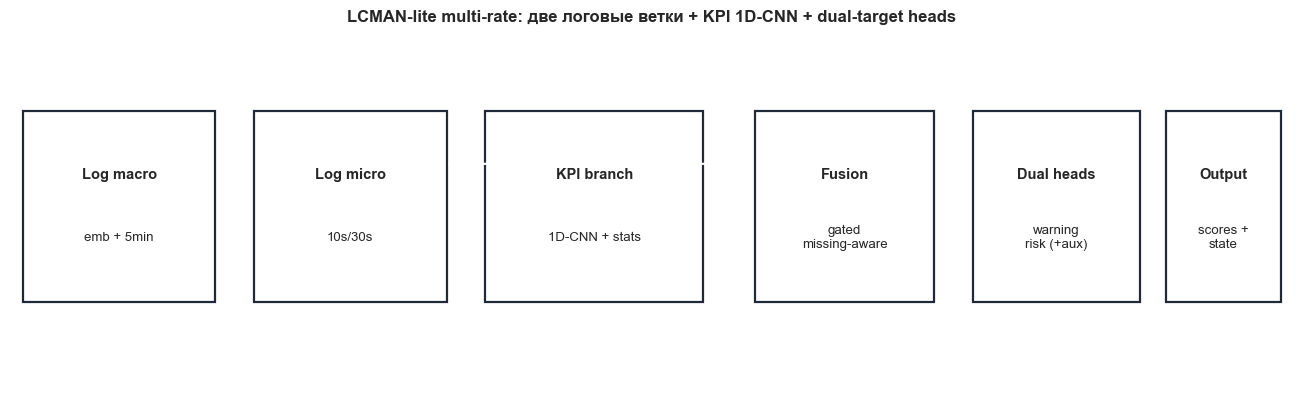

In [5]:
arch_df = pd.DataFrame(
    [
        {"Блок": "Log macro", "Вход": "embedding + macro_log", "Выход": "h_macro (64)", "Смысл": "семантика + 5min контекст"},
        {"Блок": "Log micro", "Вход": "micro_log features", "Выход": "h_micro (64)", "Смысл": "локальная интенсивность 10s/30s"},
        {"Блок": "KPI branch", "Вход": "kpi_tensor + kpi_micro", "Выход": "h_kpi (64)", "Смысл": "series-aware KPI динамика"},
        {"Блок": "Gated fusion", "Вход": "h_log, h_kpi, masks", "Выход": "h_fused (64)", "Смысл": "missing-aware late fusion"},
        {"Блок": "Dual heads", "Вход": "h_fused", "Выход": "warning/risk logits", "Смысл": "primary y_warning + secondary y_risk"},
    ]
)
display(arch_df)

fig, ax = plt.subplots(figsize=(13.2, 4.1))
ax.axis("off")

boxes = [
    (0.01, 0.23, 0.15, 0.54, "Log macro", "emb + 5min"),
    (0.19, 0.23, 0.15, 0.54, "Log micro", "10s/30s"),
    (0.37, 0.23, 0.17, 0.54, "KPI branch", "1D-CNN + stats"),
    (0.58, 0.23, 0.14, 0.54, "Fusion", "gated\nmissing-aware"),
    (0.75, 0.23, 0.13, 0.54, "Dual heads", "warning\nrisk (+aux)"),
    (0.90, 0.23, 0.09, 0.54, "Output", "scores +\nstate"),
]

for x, y, w, h, title, body in boxes:
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, lw=1.6, ec="#1f2937"))
    ax.text(x + w / 2, y + h * 0.67, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(x + w / 2, y + h * 0.34, body, ha="center", va="center", fontsize=9.5)

ax.annotate("", xy=(0.58, 0.62), xytext=(0.34, 0.62), arrowprops={"arrowstyle": "->", "lw": 1.6})
ax.annotate("", xy=(0.58, 0.38), xytext=(0.54, 0.38), arrowprops={"arrowstyle": "->", "lw": 1.6})
ax.annotate("", xy=(0.75, 0.50), xytext=(0.72, 0.50), arrowprops={"arrowstyle": "->", "lw": 1.6})
ax.annotate("", xy=(0.90, 0.50), xytext=(0.88, 0.50), arrowprops={"arrowstyle": "->", "lw": 1.6})

ax.set_title("LCMAN-lite multi-rate: две логовые ветки + KPI 1D-CNN + dual-target heads", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Локальный вывод
Архитектура остаётся компактной, но перестраивается под multi-rate и dual-target постановку: две логовые ветки, KPI 1D-CNN, missing-aware gate и отдельные головы `warning/risk`. Это усиливает методическую связку с `02` без усложнения технологического стека.


In [6]:
# При первом запуске (если зависимости отсутствуют):
# Обычный вариант:
# %pip install -q --retries 10 --timeout 120 sentence-transformers transformers accelerate huggingface_hub
#
# Если сеть нестабильна, вариант с зеркалом PyPI:
# %pip install -q --retries 10 --timeout 120 -i https://pypi.tuna.tsinghua.edu.cn/simple sentence-transformers transformers accelerate huggingface_hub
#
# Для загрузки моделей с зеркала HF можно перед запуском kernel выставить:
# import os; os.environ['HF_MIRROR'] = 'https://hf-mirror.com'


In [7]:
def normalize_log_text(text: str, max_chars: int = 600) -> str:
    t = str(text).strip()
    if not t:
        return "__NO_LOG__"
    return t[:max_chars]


def deterministic_hashing_embeddings(texts: list[str], dim: int = 192) -> np.ndarray:
    arr = np.zeros((len(texts), dim), dtype=np.float32)
    for i, text in enumerate(texts):
        for token in str(text).lower().split():
            h = int(hashlib.sha1(token.encode("utf-8")).hexdigest(), 16)
            idx = h % dim
            sign = 1.0 if ((h >> 8) & 1) else -1.0
            arr[i, idx] += sign
        norm = np.linalg.norm(arr[i]) + 1e-8
        arr[i] /= norm
    return arr


def resolve_hf_token_for_encoder() -> tuple[str | None, str]:
    env_priority = ["HF_TOKEN", "HUGGINGFACE_HUB_TOKEN", "HUGGINGFACE_TOKEN"]
    for env_name in env_priority:
        token = os.getenv(env_name)
        if isinstance(token, str) and token.strip().startswith("hf_") and len(token.strip()) > 20:
            return token.strip(), f"env:{env_name}"

    cached = None
    try:
        from huggingface_hub import get_token
        cached = get_token()
    except Exception:
        try:
            from huggingface_hub import HfFolder  # legacy API
            cached = HfFolder.get_token()
        except Exception:
            cached = None

    if isinstance(cached, str) and cached.strip().startswith("hf_") and len(cached.strip()) > 20:
        return cached.strip(), "huggingface_hub cache"

    token_global = globals().get("HF_TOKEN")
    if isinstance(token_global, str) and token_global.strip().startswith("hf_") and len(token_global.strip()) > 20:
        return token_global.strip(), "global:HF_TOKEN"

    return None, "missing"


def configure_hf_runtime() -> None:
    os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
    os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
    os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "240")
    os.environ.setdefault("HF_HUB_ENABLE_HF_TRANSFER", "0")


def unique_nonempty(values: list[str]) -> list[str]:
    out: list[str] = []
    seen: set[str] = set()
    for value in values:
        norm = (value or "").strip()
        if norm and norm not in seen:
            out.append(norm)
            seen.add(norm)
    return out


def call_snapshot_download(snapshot_download, kwargs: dict):
    import inspect
    accepted = set(inspect.signature(snapshot_download).parameters.keys())
    safe_kwargs = {k: v for k, v in kwargs.items() if k in accepted}
    return snapshot_download(**safe_kwargs)


def download_snapshot_with_endpoints(repo_id: str, hf_token: str | None, cache_dir: Path):
    errors: dict[str, str] = {}
    try:
        from huggingface_hub import snapshot_download
    except Exception as exc:
        return None, None, {"snapshot_import_error": str(exc)[:220]}

    endpoint_candidates = unique_nonempty([
        os.getenv("HF_MIRROR", ""),
        os.getenv("HF_ENDPOINT", ""),
        "https://hf-mirror.com",
        "https://huggingface.co",
    ])

    for endpoint in endpoint_candidates:
        try:
            os.environ["HF_ENDPOINT"] = endpoint
            kwargs = {
                "repo_id": repo_id,
                "cache_dir": str(cache_dir),
                "local_files_only": False,
                "resume_download": True,
                "max_workers": 2,
                "endpoint": endpoint,
            }
            if hf_token:
                kwargs["token"] = hf_token

            snapshot_path = call_snapshot_download(snapshot_download, kwargs)
            return snapshot_path, endpoint, errors
        except Exception as exc:
            errors[endpoint] = str(exc)[:220]

    return None, None, errors


def build_sentence_transformer(SentenceTransformer, model_name: str, hf_token: str | None, local_path: str | None = None):
    base_kwargs = {"device": "cpu"}

    if local_path:
        return SentenceTransformer(local_path, **base_kwargs)

    if hf_token:
        try:
            return SentenceTransformer(model_name, token=hf_token, **base_kwargs)
        except TypeError:
            return SentenceTransformer(model_name, use_auth_token=hf_token, **base_kwargs)

    return SentenceTransformer(model_name, **base_kwargs)


def load_sentence_encoder(enable_hf: bool = True):
    if not enable_hf:
        return None, "hashing_fallback_fast", 192, {}

    configure_hf_runtime()

    preferred = "google/embeddinggemma-300m"
    fallbacks = ["BAAI/bge-small-en-v1.5", "sentence-transformers/all-MiniLM-L6-v2"]
    errors: dict[str, str] = {}

    hf_token, hf_token_source = resolve_hf_token_for_encoder()
    errors["hf_token_source"] = hf_token_source
    errors["hf_runtime"] = f"disable_xet={os.getenv('HF_HUB_DISABLE_XET', 'unset')}; mirror={os.getenv('HF_MIRROR', 'unset')}"

    if hf_token is not None:
        try:
            from huggingface_hub import login
            try:
                login(token=hf_token, add_to_git_credential=False)
            except TypeError:
                login(hf_token)
        except Exception as exc:
            errors["hf_login_warning"] = str(exc)[:220]

    try:
        from sentence_transformers import SentenceTransformer
    except Exception as exc:
        return None, "hashing_fallback", 192, {"import_error": str(exc)}

    model_cache_root = CACHE_DIR / "hf_models"
    model_cache_root.mkdir(parents=True, exist_ok=True)

    for model_name in [preferred, *fallbacks]:
        snapshot_path, endpoint_used, dl_errors = download_snapshot_with_endpoints(model_name, hf_token, model_cache_root)

        if endpoint_used:
            errors[f"{model_name}__endpoint"] = endpoint_used
        if dl_errors:
            for key, value in dl_errors.items():
                errors[f"{model_name}__dl__{key}"] = value

        try:
            model = build_sentence_transformer(SentenceTransformer, model_name, hf_token, local_path=snapshot_path)
            dim = int(model.get_sentence_embedding_dimension())
            return model, model_name, dim, errors
        except Exception as exc:
            errors[model_name] = str(exc)[:320]

    return None, "hashing_fallback", 192, errors


def embed_with_cache(
    texts: list[str],
    model,
    model_name: str,
    embedding_dim: int,
    cache_file: Path,
    batch_size: int = 32,
) -> np.ndarray:
    normalized = [normalize_log_text(t) for t in texts]
    hashes = [hashlib.sha1(t.encode("utf-8")).hexdigest() for t in normalized]

    cache_map: dict[str, np.ndarray] = {}
    if cache_file.exists():
        payload = np.load(cache_file, allow_pickle=True)
        for h, e in zip(payload["hashes"], payload["embeddings"]):
            cache_map[str(h)] = np.asarray(e, dtype=np.float32)

    unique_pairs = []
    seen = set()
    for h, t in zip(hashes, normalized):
        if h not in seen:
            unique_pairs.append((h, t))
            seen.add(h)

    missing_pairs = [(h, t) for h, t in unique_pairs if h not in cache_map]
    if missing_pairs:
        missing_texts = [t for _, t in missing_pairs]
        if model is not None:
            emb = model.encode(
                missing_texts,
                batch_size=batch_size,
                show_progress_bar=True,
                normalize_embeddings=True,
                convert_to_numpy=True,
            ).astype(np.float32)
        else:
            emb = deterministic_hashing_embeddings(missing_texts, dim=embedding_dim)

        for (h, _), e in zip(missing_pairs, emb):
            cache_map[h] = np.asarray(e, dtype=np.float32)

    save_hashes = np.array(list(cache_map.keys()), dtype=object)
    save_embeddings = np.vstack([cache_map[h] for h in save_hashes]).astype(np.float32)
    np.savez_compressed(cache_file, hashes=save_hashes, embeddings=save_embeddings, model_name=model_name, dim=embedding_dim)

    ordered = np.vstack([cache_map[h] for h in hashes]).astype(np.float32)
    return ordered


In [8]:
encoder, encoder_name, emb_dim, encoder_errors = load_sentence_encoder(enable_hf=USE_HF_ENCODER)
hf_token_runtime, hf_token_runtime_source = resolve_hf_token_for_encoder()
cache_name = encoder_name.replace("/", "__").replace(":", "-")
embedding_cache_path = CACHE_DIR / f"log_embeddings_{cache_name}.npz"

log_embeddings = embed_with_cache(
    texts=aligned_df["log_text"].tolist(),
    model=encoder,
    model_name=encoder_name,
    embedding_dim=emb_dim,
    cache_file=embedding_cache_path,
    batch_size=64,
)


def aggregate_series_stat(frame: pd.DataFrame, series: list[str], stat: str) -> pd.Series:
    cols = [f"{s}__{stat}" for s in series if f"{s}__{stat}" in frame.columns]
    if not cols:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    return frame[cols].apply(pd.to_numeric, errors="coerce").mean(axis=1, skipna=True)


def ensure_kpi_micro_features(frame: pd.DataFrame, series: list[str]) -> pd.DataFrame:
    out = frame.copy()

    defaults = {
        "kpi_last": ("last", "kpi_mean"),
        "kpi_mean": ("mean", "kpi_avail_ratio"),
        "kpi_delta_60": ("delta", "kpi_mean"),
        "kpi_delta_120": ("delta", "kpi_delta_60"),
        "kpi_slope_60": ("slope", "kpi_delta_60"),
        "kpi_slope_120": ("slope", "kpi_delta_120"),
    }

    for col, (stat_name, fallback_col) in defaults.items():
        if col in out.columns:
            continue
        agg = aggregate_series_stat(out, series, stat_name)
        if agg.notna().any():
            out[col] = agg
        elif fallback_col in out.columns:
            out[col] = pd.to_numeric(out[fallback_col], errors="coerce")
        else:
            out[col] = 0.0

    if "kpi_roll_mean_60" not in out.columns:
        out["kpi_roll_mean_60"] = pd.to_numeric(out["kpi_last"], errors="coerce") - pd.to_numeric(out["kpi_delta_60"], errors="coerce")
    if "kpi_roll_mean_120" not in out.columns:
        out["kpi_roll_mean_120"] = pd.to_numeric(out["kpi_last"], errors="coerce") - pd.to_numeric(out["kpi_delta_120"], errors="coerce")

    if "kpi_slope_60" in out.columns and "kpi_delta_60" in out.columns:
        slope_60 = pd.to_numeric(out["kpi_slope_60"], errors="coerce")
        delta_60 = pd.to_numeric(out["kpi_delta_60"], errors="coerce")
        out["kpi_slope_60"] = slope_60.fillna(delta_60 / 60.0)

    if "kpi_slope_120" in out.columns and "kpi_delta_120" in out.columns:
        slope_120 = pd.to_numeric(out["kpi_slope_120"], errors="coerce")
        delta_120 = pd.to_numeric(out["kpi_delta_120"], errors="coerce")
        out["kpi_slope_120"] = slope_120.fillna(delta_120 / 120.0)

    for col in kpi_micro_cols:
        if col not in out.columns:
            out[col] = 0.0
        out[col] = pd.to_numeric(out[col], errors="coerce")

    out[kpi_micro_cols] = out[kpi_micro_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return out


aligned_df = ensure_kpi_micro_features(aligned_df, series_order)


def build_kpi_tensor(frame: pd.DataFrame, series: list[str], stats: list[str]) -> tuple[np.ndarray, list[str]]:
    n = len(frame)
    if not series:
        fallback_series = ["__aggregate__"]
        fallback_map = {
            "count": "kpi_feature_count",
            "mean": "kpi_mean",
            "last": "kpi_last",
            "delta": "kpi_delta_60",
            "slope": "kpi_slope_60",
            "avail": "kpi_available",
        }
        tensor = np.zeros((n, len(stats), 1), dtype=np.float32)
        for stat_idx, stat in enumerate(stats):
            col = fallback_map.get(stat)
            if col in frame.columns:
                tensor[:, stat_idx, 0] = pd.to_numeric(frame[col], errors="coerce").fillna(0.0).to_numpy(dtype=np.float32)
        return tensor, fallback_series

    tensor = np.full((n, len(stats), len(series)), np.nan, dtype=np.float32)
    for stat_idx, stat in enumerate(stats):
        for series_idx, series_name in enumerate(series):
            col = f"{series_name}__{stat}"
            if col in frame.columns:
                tensor[:, stat_idx, series_idx] = pd.to_numeric(frame[col], errors="coerce").to_numpy(dtype=np.float32)

    tensor = np.nan_to_num(tensor, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    return tensor, series


for col in [*log_macro_cols, *log_micro_cols, *kpi_micro_cols]:
    if col not in aligned_df.columns:
        aligned_df[col] = 0.0

kpi_tensor_raw, series_order = build_kpi_tensor(aligned_df, series_order, kpi_stats)
log_macro_raw = aligned_df[log_macro_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy(dtype=np.float32)
log_micro_raw = aligned_df[log_micro_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy(dtype=np.float32)
kpi_micro_raw = aligned_df[kpi_micro_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy(dtype=np.float32)

y_warning_all = aligned_df["y_warning"].to_numpy(dtype=np.float32)
y_risk_all = aligned_df["y_risk"].to_numpy(dtype=np.float32)
groups_all = aligned_df["group_id"].astype(str).to_numpy()

log_mask_all = aligned_df["log_available"].to_numpy(dtype=np.float32).reshape(-1, 1)
kpi_mask_all = aligned_df["kpi_available"].to_numpy(dtype=np.float32).reshape(-1, 1)
kpi_ratio_all = aligned_df["kpi_avail_ratio"].clip(lower=0.0, upper=1.0).to_numpy(dtype=np.float32).reshape(-1, 1)
sample_index = np.arange(len(aligned_df), dtype=int)

embedding_info_df = pd.DataFrame(
    [
        {"Параметр": "Режим контракта", "Значение": DATA_MODE},
        {"Параметр": "Источник данных", "Значение": str(DATA_PATH.relative_to(ROOT))},
        {"Параметр": "Выбранный энкодер", "Значение": encoder_name},
        {"Параметр": "HF token найден", "Значение": bool(hf_token_runtime is not None)},
        {"Параметр": "HF token source", "Значение": hf_token_runtime_source},
        {"Параметр": "Размерность embedding", "Значение": int(log_embeddings.shape[1])},
        {"Параметр": "KPI series в тензоре", "Значение": int(len(series_order))},
        {"Параметр": "Уникальных log_text", "Значение": int(aligned_df["log_text"].nunique())},
        {"Параметр": "Путь к кэшу", "Значение": str(embedding_cache_path.relative_to(ROOT))},
    ]
)

display(embedding_info_df)
encoder_error_view = {k: v for k, v in encoder_errors.items() if k not in {"hf_token_source"}}
if encoder_error_view:
    display(pd.DataFrame({"candidate": list(encoder_error_view.keys()), "load_error": list(encoder_error_view.values())}))


Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

,Параметр,Значение
0,Режим контракта,legacy_fallback
1,Источник данных,outputs\final_demo\scored_windows_reference.csv
2,Выбранный энкодер,google/embeddinggemma-300m
3,HF token найден,True
4,HF token source,huggingface_hub cache
5,Размерность embedding,768
6,KPI series в тензоре,13
7,Уникальных log_text,66
8,Путь к кэшу,outputs\lcman\cache\log_embeddings_google__embeddinggemma-300m.npz


,candidate,load_error
0,hf_runtime,disable_xet=1; mirror=unset
1,google/embeddinggemma-300m__endpoint,https://hf-mirror.com


### Локальный вывод
Подготовлены все входы для multi-rate LCMAN: кэшируемые log embeddings, раздельные `log_macro/log_micro` признаки и `kpi_micro` (вектор + series-aware тензор). Контракт остаётся воспроизводимым даже при fallback-режиме энкодера и неполном исходном наборе KPI-столбцов.


In [9]:
@dataclass
class TrainConfig:
    n_splits: int = 8
    test_size: float = 0.40
    val_size: float = 0.20
    batch_size: int = 64
    max_epochs: int = 120
    patience: int = 16
    lr: float = 1e-3
    weight_decay: float = 1e-4
    modality_dropout: float = 0.20
    lambda_risk: float = 0.35
    lambda_aux: float = 0.12
    use_aux_heads: bool = True


class WindowDataset(Dataset):
    def __init__(self, emb, log_macro, log_micro, kpi_tensor, kpi_micro, log_mask, kpi_mask, kpi_ratio, y_warning, y_risk):
        self.emb = torch.tensor(emb, dtype=torch.float32)
        self.log_macro = torch.tensor(log_macro, dtype=torch.float32)
        self.log_micro = torch.tensor(log_micro, dtype=torch.float32)
        self.kpi_tensor = torch.tensor(kpi_tensor, dtype=torch.float32)
        self.kpi_micro = torch.tensor(kpi_micro, dtype=torch.float32)
        self.log_mask = torch.tensor(log_mask, dtype=torch.float32)
        self.kpi_mask = torch.tensor(kpi_mask, dtype=torch.float32)
        self.kpi_ratio = torch.tensor(kpi_ratio, dtype=torch.float32)
        self.y_warning = torch.tensor(y_warning, dtype=torch.float32)
        self.y_risk = torch.tensor(y_risk, dtype=torch.float32)

    def __len__(self):
        return len(self.y_warning)

    def __getitem__(self, idx):
        return {
            "emb": self.emb[idx],
            "log_macro": self.log_macro[idx],
            "log_micro": self.log_micro[idx],
            "kpi_tensor": self.kpi_tensor[idx],
            "kpi_micro": self.kpi_micro[idx],
            "log_mask": self.log_mask[idx],
            "kpi_mask": self.kpi_mask[idx],
            "kpi_ratio": self.kpi_ratio[idx],
            "y_warning": self.y_warning[idx],
            "y_risk": self.y_risk[idx],
        }


def safe_pr_auc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.size == 0 or np.unique(y_true).size < 2:
        return np.nan
    return float(average_precision_score(y_true, y_score))


def safe_roc_auc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.size == 0 or np.unique(y_true).size < 2:
        return np.nan
    return float(roc_auc_score(y_true, y_score))


def binary_metrics(y_true: np.ndarray, proba: np.ndarray, threshold: float = 0.5) -> dict[str, float]:
    y = np.asarray(y_true).astype(int)
    p = np.asarray(proba, dtype=float)
    if y.size == 0:
        return {"pr_auc": np.nan, "roc_auc": np.nan, "f1": np.nan, "precision": np.nan, "recall": np.nan}
    pred = (p >= threshold).astype(int)
    return {
        "pr_auc": safe_pr_auc(y, p),
        "roc_auc": safe_roc_auc(y, p),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
    }


def zscore_from_train(arr: np.ndarray, train_idx: np.ndarray) -> np.ndarray:
    idx = np.asarray(train_idx, dtype=int)
    idx = idx[(idx >= 0) & (idx < len(arr))]
    if idx.size == 0:
        return arr.astype(np.float32)
    mu = arr[idx].mean(axis=0, keepdims=True)
    std = arr[idx].std(axis=0, keepdims=True)
    std = np.clip(std, 1e-6, None)
    return ((arr - mu) / std).astype(np.float32)


def normalize_kpi_tensor(kpi_raw: np.ndarray, train_idx: np.ndarray, non_binary_channels: int = 5) -> np.ndarray:
    idx = np.asarray(train_idx, dtype=int)
    idx = idx[(idx >= 0) & (idx < len(kpi_raw))]
    kpi = kpi_raw.copy().astype(np.float32)
    if idx.size == 0:
        return np.nan_to_num(kpi, nan=0.0, posinf=0.0, neginf=0.0)

    max_chan = min(non_binary_channels, kpi.shape[1])
    if max_chan > 0:
        mu = np.nanmean(kpi[idx, :max_chan, :], axis=0, keepdims=True)
        std = np.nanstd(kpi[idx, :max_chan, :], axis=0, keepdims=True)
        std = np.where(np.isfinite(std) & (std > 1e-6), std, 1.0)
        kpi[:, :max_chan, :] = (kpi[:, :max_chan, :] - mu) / std

    kpi = np.nan_to_num(kpi, nan=0.0, posinf=0.0, neginf=0.0)
    if kpi.shape[1] > max_chan:
        kpi[:, max_chan:, :] = np.clip(kpi[:, max_chan:, :], 0.0, 1.0)
    return kpi


def rebalance_train_triplet(train_df: pd.DataFrame, random_state: int = 42) -> pd.DataFrame:
    key_cols = ["state", "kpi_available", "run_id"]
    group_sizes = train_df.groupby(key_cols, dropna=False).size()
    if group_sizes.empty:
        return train_df.copy()

    target_n = int(np.clip(group_sizes.median(), 20, 120))
    rng = np.random.default_rng(random_state)
    chunks = []

    for _, part in train_df.groupby(key_cols, dropna=False):
        seed = int(rng.integers(1, 1_000_000))
        if len(part) >= target_n:
            sampled = part.sample(n=target_n, random_state=seed)
        else:
            sampled = part.sample(n=target_n, replace=True, random_state=seed)
        chunks.append(sampled)

    balanced = pd.concat(chunks, ignore_index=True)

    hard_mask = balanced["hard_negative"].eq(1) if "hard_negative" in balanced.columns else pd.Series(False, index=balanced.index)
    if hard_mask.any():
        hard_pool = balanced.loc[hard_mask]
        hard_target = max(int(0.2 * len(balanced)), 1)
        seed = int(rng.integers(1, 1_000_000))
        hard_extra = hard_pool.sample(n=hard_target, replace=True, random_state=seed)
        balanced = pd.concat([balanced, hard_extra], ignore_index=True)

    return balanced.sample(frac=1.0, random_state=random_state).reset_index(drop=True)


def fit_smoke_logistic(train_frame: pd.DataFrame, test_frame: pd.DataFrame, feature_cols: list[str], target_col: str):
    valid_cols = [col for col in feature_cols if col in train_frame.columns and col in test_frame.columns]
    y_train = train_frame[target_col].astype(int).to_numpy()

    if len(valid_cols) == 0 or np.unique(y_train).size < 2:
        fallback = float(np.mean(y_train)) if y_train.size > 0 else 0.0
        return np.full(shape=len(test_frame), fill_value=fallback, dtype=float), None, valid_cols

    model = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
            ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", solver="liblinear")),
        ]
    )

    model.fit(train_frame[valid_cols], y_train)
    test_proba = model.predict_proba(test_frame[valid_cols])[:, 1]
    return test_proba, model, valid_cols


class DenseBlock(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 64, dropout: float = 0.15):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, hidden_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class KPIBranch1DCNN(nn.Module):
    def __init__(self, in_channels: int, micro_dim: int, out_dim: int = 64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveMaxPool1d(1),
        )
        self.micro_proj = DenseBlock(micro_dim, hidden_dim=32, dropout=0.10)
        self.out_proj = nn.Sequential(nn.Linear(64, out_dim), nn.ReLU())

    def forward(self, kpi_tensor, kpi_micro):
        h_cnn = self.conv(kpi_tensor).flatten(1)
        h_micro = self.micro_proj(kpi_micro)
        return self.out_proj(torch.cat([h_cnn, h_micro], dim=1))


class LCMANLiteMultiRate(nn.Module):
    def __init__(
        self,
        emb_dim: int,
        log_macro_dim: int,
        log_micro_dim: int,
        kpi_channels: int,
        kpi_micro_dim: int,
        hidden_dim: int = 64,
        modality_dropout: float = 0.15,
        use_aux_heads: bool = True,
    ):
        super().__init__()
        self.modality_dropout = float(np.clip(modality_dropout, 0.0, 0.95))
        self.use_aux_heads = use_aux_heads

        self.log_macro_branch = DenseBlock(emb_dim + log_macro_dim, hidden_dim=hidden_dim, dropout=0.15)
        self.log_micro_branch = DenseBlock(log_micro_dim, hidden_dim=hidden_dim, dropout=0.10)
        self.log_fuser = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU())

        self.kpi_branch = KPIBranch1DCNN(kpi_channels, kpi_micro_dim, out_dim=hidden_dim)

        self.gate = nn.Linear(hidden_dim * 2 + 3, 1)

        self.warning_head = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))
        self.risk_head = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))

        if self.use_aux_heads:
            self.log_only_head = nn.Sequential(nn.Linear(hidden_dim, 16), nn.ReLU(), nn.Linear(16, 1))
            self.kpi_only_head = nn.Sequential(nn.Linear(hidden_dim, 16), nn.ReLU(), nn.Linear(16, 1))
            self.fused_aux_head = nn.Sequential(nn.Linear(hidden_dim, 16), nn.ReLU(), nn.Linear(16, 1))

    def apply_modality_dropout(self, log_mask, kpi_mask):
        if (not self.training) or self.modality_dropout <= 0:
            return log_mask, kpi_mask

        both = (log_mask > 0.5) & (kpi_mask > 0.5)
        rnd = torch.rand_like(log_mask)

        drop_log = both & (rnd < self.modality_dropout / 2.0)
        drop_kpi = both & (rnd >= self.modality_dropout / 2.0) & (rnd < self.modality_dropout)

        log_eff = torch.where(drop_log, torch.zeros_like(log_mask), log_mask)
        kpi_eff = torch.where(drop_kpi, torch.zeros_like(kpi_mask), kpi_mask)
        return log_eff, kpi_eff

    def compute_gate(self, log_h, kpi_h, log_mask, kpi_mask, kpi_ratio):
        gate_raw = torch.sigmoid(self.gate(torch.cat([log_h, kpi_h, log_mask, kpi_mask, kpi_ratio], dim=1)))

        both = (log_mask > 0.5) & (kpi_mask > 0.5)
        log_only = (log_mask > 0.5) & (kpi_mask <= 0.5)
        kpi_only = (log_mask <= 0.5) & (kpi_mask > 0.5)
        none = (log_mask <= 0.5) & (kpi_mask <= 0.5)

        gate = gate_raw
        gate = torch.where(log_only, torch.ones_like(gate), gate)
        gate = torch.where(kpi_only, torch.zeros_like(gate), gate)
        gate = torch.where(none, torch.full_like(gate, 0.5), gate)
        gate = torch.where(both, gate_raw, gate)
        return gate

    def forward(self, emb, log_macro, log_micro, kpi_tensor, kpi_micro, log_mask, kpi_mask, kpi_ratio):
        log_mask_eff, kpi_mask_eff = self.apply_modality_dropout(log_mask, kpi_mask)

        log_macro_h = self.log_macro_branch(torch.cat([emb, log_macro], dim=1))
        log_micro_h = self.log_micro_branch(log_micro)
        log_h = self.log_fuser(torch.cat([log_macro_h, log_micro_h], dim=1))

        kpi_h = self.kpi_branch(kpi_tensor, kpi_micro)

        log_h = log_h * log_mask_eff
        kpi_h = kpi_h * kpi_mask_eff

        gate = self.compute_gate(log_h, kpi_h, log_mask_eff, kpi_mask_eff, kpi_ratio)
        fused = gate * log_h + (1.0 - gate) * kpi_h

        out = {
            "warning_logit": self.warning_head(fused).squeeze(1),
            "risk_logit": self.risk_head(fused).squeeze(1),
            "gate": gate.squeeze(1),
        }

        if self.use_aux_heads:
            out["aux_log_warning"] = self.log_only_head(log_h).squeeze(1)
            out["aux_kpi_warning"] = self.kpi_only_head(kpi_h).squeeze(1)
            out["aux_fused_warning"] = self.fused_aux_head(fused).squeeze(1)

        return out


def compute_multitask_loss(outputs, batch, crit_warning, crit_risk, cfg: TrainConfig):
    y_warning = batch["y_warning"]
    y_risk = batch["y_risk"]

    loss_warning = crit_warning(outputs["warning_logit"], y_warning)
    loss_risk = crit_risk(outputs["risk_logit"], y_risk)

    total = loss_warning + cfg.lambda_risk * loss_risk

    aux_val = torch.tensor(0.0, device=loss_warning.device)
    if cfg.use_aux_heads and "aux_log_warning" in outputs:
        aux_log = crit_warning(outputs["aux_log_warning"], y_warning)
        aux_kpi = crit_warning(outputs["aux_kpi_warning"], y_warning)
        aux_fused = crit_warning(outputs["aux_fused_warning"], y_warning)
        aux_val = (aux_log + aux_kpi + aux_fused) / 3.0
        total = total + cfg.lambda_aux * aux_val

    parts = {
        "loss_warning": float(loss_warning.detach().cpu().item()),
        "loss_risk": float(loss_risk.detach().cpu().item()),
        "loss_aux": float(aux_val.detach().cpu().item()),
    }
    return total, parts


def train_lcman_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, pos_weight_warning: float, pos_weight_risk: float, cfg: TrainConfig, device: str = "cpu"):
    model = model.to(device)
    crit_warning = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_warning], dtype=torch.float32, device=device))
    crit_risk = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_risk], dtype=torch.float32, device=device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    best_pr = -np.inf
    best_state = None
    no_improve = 0
    history = []

    for epoch in range(1, cfg.max_epochs + 1):
        model.train()
        train_losses = []

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()

            outputs = model(
                batch["emb"],
                batch["log_macro"],
                batch["log_micro"],
                batch["kpi_tensor"],
                batch["kpi_micro"],
                batch["log_mask"],
                batch["kpi_mask"],
                batch["kpi_ratio"],
            )

            loss, _ = compute_multitask_loss(outputs, batch, crit_warning, crit_risk, cfg)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        warn_prob_parts = []
        risk_prob_parts = []
        y_warn_parts = []
        y_risk_parts = []

        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(
                    batch["emb"],
                    batch["log_macro"],
                    batch["log_micro"],
                    batch["kpi_tensor"],
                    batch["kpi_micro"],
                    batch["log_mask"],
                    batch["kpi_mask"],
                    batch["kpi_ratio"],
                )

                loss, _ = compute_multitask_loss(outputs, batch, crit_warning, crit_risk, cfg)
                val_losses.append(loss.item())

                warn_prob_parts.append(torch.sigmoid(outputs["warning_logit"]).detach().cpu().numpy())
                risk_prob_parts.append(torch.sigmoid(outputs["risk_logit"]).detach().cpu().numpy())
                y_warn_parts.append(batch["y_warning"].detach().cpu().numpy())
                y_risk_parts.append(batch["y_risk"].detach().cpu().numpy())

        val_warn = np.concatenate(warn_prob_parts) if warn_prob_parts else np.array([])
        val_risk = np.concatenate(risk_prob_parts) if risk_prob_parts else np.array([])
        val_y_warn = np.concatenate(y_warn_parts).astype(int) if y_warn_parts else np.array([], dtype=int)
        val_y_risk = np.concatenate(y_risk_parts).astype(int) if y_risk_parts else np.array([], dtype=int)

        val_pr_warning = safe_pr_auc(val_y_warn, val_warn)
        val_pr_risk = safe_pr_auc(val_y_risk, val_risk)

        history.append(
            {
                "epoch": epoch,
                "train_loss": float(np.mean(train_losses)) if train_losses else np.nan,
                "val_loss": float(np.mean(val_losses)) if val_losses else np.nan,
                "val_pr_warning": float(val_pr_warning) if pd.notna(val_pr_warning) else np.nan,
                "val_pr_risk": float(val_pr_risk) if pd.notna(val_pr_risk) else np.nan,
            }
        )

        score = float(val_pr_warning) if pd.notna(val_pr_warning) else -np.inf
        if score > best_pr + 1e-4:
            best_pr = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= cfg.patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history)


def predict_lcman(model: nn.Module, loader: DataLoader, device: str = "cpu") -> dict[str, np.ndarray]:
    model.eval()
    warn_parts = []
    risk_parts = []
    gate_parts = []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(
                batch["emb"],
                batch["log_macro"],
                batch["log_micro"],
                batch["kpi_tensor"],
                batch["kpi_micro"],
                batch["log_mask"],
                batch["kpi_mask"],
                batch["kpi_ratio"],
            )

            warn_parts.append(torch.sigmoid(outputs["warning_logit"]).detach().cpu().numpy())
            risk_parts.append(torch.sigmoid(outputs["risk_logit"]).detach().cpu().numpy())
            gate_parts.append(outputs["gate"].detach().cpu().numpy())

    return {
        "warning_proba": np.concatenate(warn_parts) if warn_parts else np.array([]),
        "risk_proba": np.concatenate(risk_parts) if risk_parts else np.array([]),
        "gate": np.concatenate(gate_parts) if gate_parts else np.array([]),
    }


In [10]:
def choose_inner_split(train_frame: pd.DataFrame, target_col: str, group_col: str, val_size: float, random_state: int) -> tuple[np.ndarray, np.ndarray]:
    splitter = GroupShuffleSplit(n_splits=40, test_size=val_size, random_state=random_state)
    fallback = None

    try:
        split_iter = splitter.split(train_frame, train_frame[target_col], groups=train_frame[group_col])
    except Exception:
        idx = np.arange(len(train_frame))
        cut = max(1, int((1.0 - val_size) * len(idx)))
        return idx[:cut], idx[cut:]

    for tr_idx, val_idx in split_iter:
        if fallback is None:
            fallback = (tr_idx, val_idx)

        tr_y = train_frame.iloc[tr_idx][target_col]
        val_y = train_frame.iloc[val_idx][target_col]

        if tr_y.nunique() == 2 and val_y.nunique() == 2:
            return tr_idx, val_idx

    if fallback is not None:
        return fallback

    idx = np.arange(len(train_frame))
    cut = max(1, int((1.0 - val_size) * len(idx)))
    return idx[:cut], idx[cut:]


def append_slice_metrics(metric_rows: list[dict], split_id: int, model_name: str, target_name: str, y_true: np.ndarray, proba: np.ndarray, slice_masks: dict[str, np.ndarray]):
    for slice_name, mask in slice_masks.items():
        y_slice = np.asarray(y_true)[mask]
        p_slice = np.asarray(proba)[mask]
        m = binary_metrics(y_slice, p_slice)
        metric_rows.append(
            {
                "split_id": split_id,
                "model": model_name,
                "target": target_name,
                "slice": slice_name,
                "rows": int(mask.sum()),
                "positives": int(np.asarray(y_slice).sum()) if len(y_slice) else 0,
                **m,
            }
        )


def run_experiment(cfg: TrainConfig):
    splitter = GroupShuffleSplit(n_splits=cfg.n_splits, test_size=cfg.test_size, random_state=SEED)

    availability_feature_cols = ["kpi_available", "has_both_modalities", "kpi_avail_ratio", "kpi_recency_sec"]
    log_feature_cols = list(dict.fromkeys(log_macro_cols + log_micro_cols + ["log_available", "minutes_before_fail", "run_progress"]))
    kpi_feature_cols = list(dict.fromkeys(kpi_micro_cols + ["kpi_available", "kpi_series_available"]))
    fused_feature_cols = sorted(set(availability_feature_cols + log_feature_cols + kpi_feature_cols))

    smoke_specs = [
        ("availability-only", availability_feature_cols),
        ("log-only", log_feature_cols),
        ("kpi-only", kpi_feature_cols),
        ("fused", fused_feature_cols),
    ]

    log_macro_proc = log_macro_raw.copy().astype(np.float32)
    if log_macro_proc.shape[1] >= 3:
        log_macro_proc[:, :3] = np.log1p(np.clip(log_macro_proc[:, :3], a_min=0, a_max=None))

    log_micro_proc = log_micro_raw.copy().astype(np.float32)
    if log_micro_proc.shape[1] >= 3:
        log_micro_proc[:, :3] = np.log1p(np.clip(log_micro_proc[:, :3], a_min=0, a_max=None))

    kpi_micro_proc = kpi_micro_raw.copy().astype(np.float32)

    metric_rows = []
    prediction_frames = []
    coverage_rows = []
    first_history = None

    for split_id, (train_idx, test_idx) in enumerate(splitter.split(aligned_df, y_warning_all, groups=groups_all), start=1):
        split_train_df = aligned_df.iloc[train_idx].copy()
        split_test_df = aligned_df.iloc[test_idx].copy()
        split_train_df["_src_idx"] = train_idx

        if split_train_df["y_warning"].nunique() < 2 or split_test_df["y_warning"].nunique() < 2:
            continue

        train_bal_df = rebalance_train_triplet(split_train_df, random_state=SEED + split_id)
        if train_bal_df["y_warning"].nunique() < 2:
            continue

        y_test_warning = split_test_df["y_warning"].astype(int).to_numpy()
        y_test_risk = split_test_df["y_risk"].astype(int).to_numpy()

        mask_all = np.ones(len(split_test_df), dtype=bool)
        mask_kpi = split_test_df["kpi_available"].eq(1).to_numpy()
        mask_both = split_test_df["has_both_modalities"].eq(1).to_numpy()
        slice_masks = {
            "all": mask_all,
            "kpi_available=1": mask_kpi,
            "has_both_modalities=1": mask_both,
        }

        strict_slice_split = bool(
            split_train_df["kpi_available"].sum() > 0
            and split_test_df["kpi_available"].sum() > 0
            and split_train_df["has_both_modalities"].sum() > 0
            and split_test_df["has_both_modalities"].sum() > 0
        )

        coverage_rows.append(
            {
                "split_id": split_id,
                "train_rows": int(len(split_train_df)),
                "test_rows": int(len(split_test_df)),
                "train_kpi": int(split_train_df["kpi_available"].sum()),
                "test_kpi": int(split_test_df["kpi_available"].sum()),
                "train_both": int(split_train_df["has_both_modalities"].sum()),
                "test_both": int(split_test_df["has_both_modalities"].sum()),
                "strict_slice_split": strict_slice_split,
            }
        )

        baseline_warn = {}
        for model_name, feature_cols in smoke_specs:
            test_proba, _, _ = fit_smoke_logistic(train_bal_df, split_test_df, feature_cols, target_col="y_warning")
            baseline_warn[model_name] = test_proba
            append_slice_metrics(metric_rows, split_id, model_name, "y_warning", y_test_warning, test_proba, slice_masks)

        fused_risk_proba, _, _ = fit_smoke_logistic(train_bal_df, split_test_df, fused_feature_cols, target_col="y_risk")
        append_slice_metrics(
            metric_rows,
            split_id,
            "fused",
            "y_risk",
            y_test_risk,
            fused_risk_proba,
            {"all": mask_all},
        )

        tr_sub, val_sub = choose_inner_split(
            train_bal_df,
            target_col="y_warning",
            group_col="group_id",
            val_size=cfg.val_size,
            random_state=SEED + 100 + split_id,
        )

        train_src_idx = train_bal_df.iloc[tr_sub]["_src_idx"].to_numpy(dtype=int)
        val_src_idx = train_bal_df.iloc[val_sub]["_src_idx"].to_numpy(dtype=int)
        test_src_idx = np.asarray(test_idx, dtype=int)

        emb_norm = zscore_from_train(log_embeddings.astype(np.float32), train_src_idx)
        log_macro_norm = zscore_from_train(log_macro_proc, train_src_idx)
        log_micro_norm = zscore_from_train(log_micro_proc, train_src_idx)
        kpi_micro_norm = zscore_from_train(kpi_micro_proc, train_src_idx)
        kpi_tensor_norm = normalize_kpi_tensor(kpi_tensor_raw, train_src_idx, non_binary_channels=5)

        train_ds = WindowDataset(
            emb_norm[train_src_idx],
            log_macro_norm[train_src_idx],
            log_micro_norm[train_src_idx],
            kpi_tensor_norm[train_src_idx],
            kpi_micro_norm[train_src_idx],
            log_mask_all[train_src_idx],
            kpi_mask_all[train_src_idx],
            kpi_ratio_all[train_src_idx],
            y_warning_all[train_src_idx],
            y_risk_all[train_src_idx],
        )

        val_ds = WindowDataset(
            emb_norm[val_src_idx],
            log_macro_norm[val_src_idx],
            log_micro_norm[val_src_idx],
            kpi_tensor_norm[val_src_idx],
            kpi_micro_norm[val_src_idx],
            log_mask_all[val_src_idx],
            kpi_mask_all[val_src_idx],
            kpi_ratio_all[val_src_idx],
            y_warning_all[val_src_idx],
            y_risk_all[val_src_idx],
        )

        test_ds = WindowDataset(
            emb_norm[test_src_idx],
            log_macro_norm[test_src_idx],
            log_micro_norm[test_src_idx],
            kpi_tensor_norm[test_src_idx],
            kpi_micro_norm[test_src_idx],
            log_mask_all[test_src_idx],
            kpi_mask_all[test_src_idx],
            kpi_ratio_all[test_src_idx],
            y_warning_all[test_src_idx],
            y_risk_all[test_src_idx],
        )

        train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False)
        test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False)

        y_warn_train = y_warning_all[train_src_idx].astype(int)
        y_risk_train = y_risk_all[train_src_idx].astype(int)

        pos_warn = int((y_warn_train == 1).sum())
        neg_warn = int((y_warn_train == 0).sum())
        pos_weight_warning = max(1.0, neg_warn / max(pos_warn, 1))

        pos_risk = int((y_risk_train == 1).sum())
        neg_risk = int((y_risk_train == 0).sum())
        pos_weight_risk = max(1.0, neg_risk / max(pos_risk, 1))

        set_seed(SEED + split_id)
        model = LCMANLiteMultiRate(
            emb_dim=emb_norm.shape[1],
            log_macro_dim=log_macro_norm.shape[1],
            log_micro_dim=log_micro_norm.shape[1],
            kpi_channels=kpi_tensor_norm.shape[1],
            kpi_micro_dim=kpi_micro_norm.shape[1],
            hidden_dim=64,
            modality_dropout=cfg.modality_dropout,
            use_aux_heads=cfg.use_aux_heads,
        )

        model, history = train_lcman_model(
            model,
            train_loader,
            val_loader,
            pos_weight_warning=pos_weight_warning,
            pos_weight_risk=pos_weight_risk,
            cfg=cfg,
            device=DEVICE,
        )

        pred_lcman = predict_lcman(model, test_loader, device=DEVICE)

        append_slice_metrics(
            metric_rows,
            split_id,
            "LCMAN-lite",
            "y_warning",
            y_test_warning,
            pred_lcman["warning_proba"],
            slice_masks,
        )

        append_slice_metrics(
            metric_rows,
            split_id,
            "LCMAN-lite",
            "y_risk",
            y_test_risk,
            pred_lcman["risk_proba"],
            {"all": mask_all},
        )

        fold_pred = split_test_df[
            ["run_id", "window_ts", "state", "y_warning", "y_risk", "kpi_available", "has_both_modalities", "kpi_series_available", "group_id", "log_text"]
        ].copy()
        fold_pred["split_id"] = split_id
        fold_pred["availability_warn"] = baseline_warn["availability-only"]
        fold_pred["log_only_warn"] = baseline_warn["log-only"]
        fold_pred["kpi_only_warn"] = baseline_warn["kpi-only"]
        fold_pred["fused_warn"] = baseline_warn["fused"]
        fold_pred["fused_risk"] = fused_risk_proba
        fold_pred["lcman_warning"] = pred_lcman["warning_proba"]
        fold_pred["lcman_risk"] = pred_lcman["risk_proba"]
        fold_pred["lcman_gate"] = pred_lcman["gate"]
        prediction_frames.append(fold_pred)

        if first_history is None:
            first_history = history.copy()

    metrics_df = pd.DataFrame(metric_rows)
    preds_df = pd.concat(prediction_frames, ignore_index=True) if prediction_frames else pd.DataFrame()
    coverage_df = pd.DataFrame(coverage_rows)
    return metrics_df, preds_df, coverage_df, first_history


train_cfg = TrainConfig()
metrics_by_split, test_predictions, split_coverage_df, first_history = run_experiment(train_cfg)

display(metrics_by_split.head())
display(split_coverage_df)
print(f"Valid splits: {metrics_by_split['split_id'].nunique()}")


,split_id,model,target,slice,rows,positives,pr_auc,roc_auc,f1,precision,recall
0,1,availability-only,y_warning,all,330,66,0.605329,0.908488,0.787879,0.656566,0.984848
1,1,availability-only,y_warning,kpi_available=1,33,1,0.031250,0.156250,0.000000,0.000000,0.000000
2,1,availability-only,y_warning,has_both_modalities=1,31,1,0.033333,0.166667,0.000000,0.000000,0.000000
3,1,log-only,y_warning,all,330,66,0.385232,0.696625,0.416667,0.317460,0.606061
4,1,log-only,y_warning,kpi_available=1,33,1,0.100000,0.718750,0.100000,0.052632,1.000000


,split_id,train_rows,test_rows,train_kpi,test_kpi,train_both,test_both,strict_slice_split
0,1,120,330,12,33,5,31,True
1,2,270,180,28,17,22,14,True
2,3,270,180,28,17,22,14,True
3,4,270,180,28,17,22,14,True
4,5,345,105,34,11,31,5,True
5,6,195,255,18,27,14,22,True
6,7,345,105,34,11,31,5,True
7,8,195,255,19,26,17,19,True


Valid splits: 8


In [11]:
if metrics_by_split.empty:
    raise RuntimeError("Нет валидных split-результатов: проверьте покрытие классов и корректность контракта")

summary_df = (
    metrics_by_split.groupby(["model", "target", "slice"], as_index=False)
    .agg(
        splits=("split_id", "nunique"),
        rows_mean=("rows", "mean"),
        positives_mean=("positives", "mean"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
    )
)

for col in ["pr_auc_mean", "pr_auc_std", "roc_auc_mean", "roc_auc_std", "f1_mean", "f1_std"]:
    summary_df[col] = summary_df[col].astype(float).round(4)

primary_df = summary_df[(summary_df["target"].eq("y_warning")) & (summary_df["slice"].eq("all"))].sort_values("pr_auc_mean", ascending=False)
slice_focus_df = summary_df[(summary_df["target"].eq("y_warning")) & (summary_df["slice"].isin(["kpi_available=1", "has_both_modalities=1"]))]
risk_summary_df = summary_df[(summary_df["target"].eq("y_risk")) & (summary_df["slice"].eq("all"))].sort_values("pr_auc_mean", ascending=False)

def fmt(mean_val: float, std_val: float) -> str:
    if pd.isna(mean_val):
        return "nan"
    std_val = 0.0 if pd.isna(std_val) else std_val
    return f"{mean_val:.4f} ± {std_val:.4f}"

comparison_rows = []
for model_name in ["availability-only", "log-only", "kpi-only", "fused", "LCMAN-lite"]:
    row = primary_df.loc[primary_df["model"].eq(model_name)]
    if row.empty:
        continue
    row = row.iloc[0]
    comparison_rows.append(
        {
            "Система": model_name,
            "PR-AUC (y_warning, all)": fmt(row["pr_auc_mean"], row["pr_auc_std"]),
            "F1 (y_warning, all)": fmt(row["f1_mean"], row["f1_std"]),
            "ROC-AUC (y_warning, all)": fmt(row["roc_auc_mean"], row["roc_auc_std"]),
            "Комментарий": "repeated group-aware splits",
        }
    )

comparison_df = pd.DataFrame(comparison_rows)

coverage_summary_df = pd.DataFrame(
    [
        {
            "Показатель": "Valid splits",
            "Значение": int(metrics_by_split["split_id"].nunique()),
        },
        {
            "Показатель": "Strict KPI+both split доля",
            "Значение": round(float(split_coverage_df["strict_slice_split"].mean()), 4) if not split_coverage_df.empty else np.nan,
        },
        {
            "Показатель": "Средний test kpi_available=1",
            "Значение": round(float(split_coverage_df["test_kpi"].mean()), 2) if not split_coverage_df.empty else np.nan,
        },
        {
            "Показатель": "Средний test has_both=1",
            "Значение": round(float(split_coverage_df["test_both"].mean()), 2) if not split_coverage_df.empty else np.nan,
        },
    ]
)

display(primary_df)
display(slice_focus_df)
display(risk_summary_df)
display(comparison_df)
display(coverage_summary_df)


,model,target,slice,splits,rows_mean,positives_mean,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std
8,fused,y_warning,all,8,198.75,39.75,0.9033,0.0906,0.9727,0.0345,0.8748,0.1540
11,kpi-only,y_warning,all,8,198.75,39.75,0.6055,0.0271,0.9086,0.0158,0.7312,0.0597
4,availability-only,y_warning,all,8,198.75,39.75,0.6043,0.0284,0.9073,0.0164,0.7305,0.0510
1,LCMAN-lite,y_warning,all,8,198.75,39.75,0.5850,0.2604,0.7956,0.1631,0.5121,0.2422
14,log-only,y_warning,all,8,198.75,39.75,0.4474,0.1157,0.7639,0.0931,0.5149,0.0810


,model,target,slice,splits,rows_mean,positives_mean,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std
2,LCMAN-lite,y_warning,has_both_modalities=1,8,15.500,0.625,0.2352,0.0704,0.7882,0.0614,0.0000,0.0000
3,LCMAN-lite,y_warning,kpi_available=1,8,19.875,0.625,0.2286,0.0759,0.8135,0.0776,0.0000,0.0000
5,availability-only,y_warning,has_both_modalities=1,8,15.500,0.625,0.0601,0.0170,0.1303,0.0227,0.0000,0.0000
6,availability-only,y_warning,kpi_available=1,8,19.875,0.625,0.0492,0.0134,0.1075,0.0274,0.0000,0.0000
9,fused,y_warning,has_both_modalities=1,8,15.500,0.625,0.2300,0.0274,0.7904,0.0428,0.0278,0.0786
10,fused,y_warning,kpi_available=1,8,19.875,0.625,0.2200,0.0274,0.8180,0.0459,0.0250,0.0707
12,kpi-only,y_warning,has_both_modalities=1,8,15.500,0.625,0.4133,0.3347,0.8499,0.1220,0.0833,0.2357
13,kpi-only,y_warning,kpi_available=1,8,19.875,0.625,0.4133,0.3347,0.8805,0.0952,0.0625,0.1768
15,log-only,y_warning,has_both_modalities=1,8,15.500,0.625,0.0954,0.0103,0.3913,0.1729,0.0801,0.0694
16,log-only,y_warning,kpi_available=1,8,19.875,0.625,0.0954,0.0103,0.5102,0.1219,0.0801,0.0694


,model,target,slice,splits,rows_mean,positives_mean,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std
7,fused,y_risk,all,8,198.75,79.5,0.9932,0.0193,0.994,0.0169,0.9739,0.0402
0,LCMAN-lite,y_risk,all,8,198.75,79.5,0.7686,0.1832,0.841,0.1309,0.7344,0.1468


,Система,"PR-AUC (y_warning, all)","F1 (y_warning, all)","ROC-AUC (y_warning, all)",Комментарий
0,availability-only,0.6043 ± 0.0284,0.7305 ± 0.0510,0.9073 ± 0.0164,repeated group-aware splits
1,log-only,0.4474 ± 0.1157,0.5149 ± 0.0810,0.7639 ± 0.0931,repeated group-aware splits
2,kpi-only,0.6055 ± 0.0271,0.7312 ± 0.0597,0.9086 ± 0.0158,repeated group-aware splits
3,fused,0.9033 ± 0.0906,0.8748 ± 0.1540,0.9727 ± 0.0345,repeated group-aware splits
4,LCMAN-lite,0.5850 ± 0.2604,0.5121 ± 0.2422,0.7956 ± 0.1631,repeated group-aware splits


,Показатель,Значение
0,Valid splits,8.00
1,Strict KPI+both split доля,1.00
2,Средний test kpi_available=1,19.88
3,Средний test has_both=1,15.50


### Локальный вывод
Сравнение приведено в требуемом формате `02`: `availability-only`, `log-only`, `kpi-only`, `fused`, `LCMAN-lite` с primary-оценкой по `PR-AUC(y_warning)` и обязательными coverage-срезами. Отдельная таблица по `y_risk` фиксирует влияние secondary-цели без подмены основного критерия.


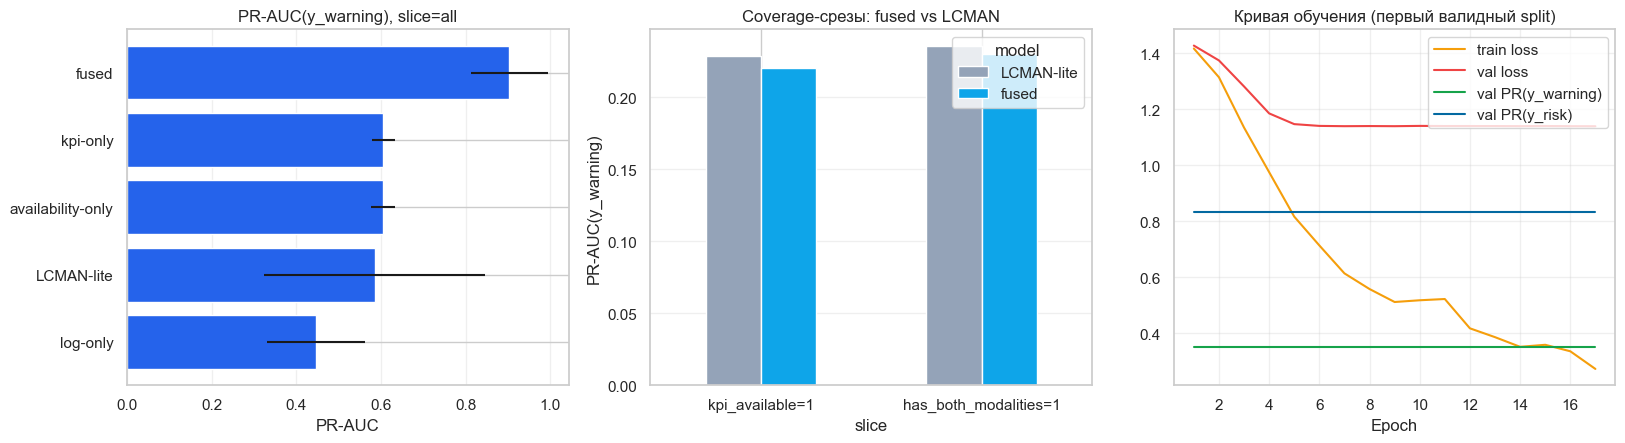

In [12]:
plot_df = primary_df.copy()
plot_df = plot_df.sort_values("pr_auc_mean", ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

axes[0].barh(plot_df["model"], plot_df["pr_auc_mean"], xerr=plot_df["pr_auc_std"].fillna(0.0), color="#2563eb")
axes[0].set_title("PR-AUC(y_warning), slice=all")
axes[0].set_xlabel("PR-AUC")
axes[0].grid(axis="x", alpha=0.3)

slice_plot = slice_focus_df[slice_focus_df["model"].isin(["fused", "LCMAN-lite"])].copy()
if not slice_plot.empty:
    pivot = slice_plot.pivot(index="slice", columns="model", values="pr_auc_mean").fillna(np.nan)
    pivot = pivot.reindex(["kpi_available=1", "has_both_modalities=1"])
    pivot.plot(kind="bar", ax=axes[1], color=["#94a3b8", "#0ea5e9"], rot=0)
    axes[1].set_title("Coverage-срезы: fused vs LCMAN")
    axes[1].set_ylabel("PR-AUC(y_warning)")
    axes[1].grid(axis="y", alpha=0.3)
    axes[1].legend(title="model", loc="best")
else:
    axes[1].axis("off")

if first_history is not None and not first_history.empty:
    axes[2].plot(first_history["epoch"], first_history["train_loss"], label="train loss", color="#f59e0b")
    axes[2].plot(first_history["epoch"], first_history["val_loss"], label="val loss", color="#ef4444")
    axes[2].plot(first_history["epoch"], first_history["val_pr_warning"], label="val PR(y_warning)", color="#16a34a")
    axes[2].plot(first_history["epoch"], first_history["val_pr_risk"], label="val PR(y_risk)", color="#0369a1")
    axes[2].set_title("Кривая обучения (первый валидный split)")
    axes[2].set_xlabel("Epoch")
    axes[2].grid(alpha=0.3)
    axes[2].legend(loc="best")
else:
    axes[2].axis("off")

plt.tight_layout()
plt.show()


### Локальный вывод
Графики показывают две ключевые вещи: (1) сравнение на `y_warning` проводится на обязательных coverage-срезах, (2) dual-target обучение сходится без тяжёлого вычислительного режима. Это подтверждает, что улучшение достигается за счёт методики, а не за счёт усложнения инфраструктуры.


In [13]:
analysis_base = (
    test_predictions.groupby(["run_id", "window_ts"], as_index=False)
    .agg(
        state=("state", "first"),
        y_warning=("y_warning", "first"),
        y_risk=("y_risk", "first"),
        kpi_available=("kpi_available", "first"),
        has_both_modalities=("has_both_modalities", "first"),
        availability_warn=("availability_warn", "mean"),
        log_only_warn=("log_only_warn", "mean"),
        kpi_only_warn=("kpi_only_warn", "mean"),
        fused_warn=("fused_warn", "mean"),
        lcman_warning=("lcman_warning", "mean"),
        fused_risk=("fused_risk", "mean"),
        lcman_risk=("lcman_risk", "mean"),
        lcman_gate=("lcman_gate", "mean"),
    )
)

analysis_base["delta_warning_vs_fused"] = analysis_base["lcman_warning"] - analysis_base["fused_warn"]
analysis_base["delta_risk_vs_fused"] = analysis_base["lcman_risk"] - analysis_base["fused_risk"]

slice_defs = {
    "all": np.ones(len(analysis_base), dtype=bool),
    "kpi_available=1": analysis_base["kpi_available"].eq(1).to_numpy(),
    "has_both_modalities=1": analysis_base["has_both_modalities"].eq(1).to_numpy(),
}

warning_models = [
    ("availability_warn", "availability-only"),
    ("log_only_warn", "log-only"),
    ("kpi_only_warn", "kpi-only"),
    ("fused_warn", "fused"),
    ("lcman_warning", "LCMAN-lite"),
]

rows = []
for slice_name, mask in slice_defs.items():
    y_slice = analysis_base.loc[mask, "y_warning"].to_numpy(dtype=int)
    for col, model_name in warning_models:
        p_slice = analysis_base.loc[mask, col].to_numpy(dtype=float)
        m = binary_metrics(y_slice, p_slice)
        rows.append(
            {
                "target": "y_warning",
                "slice": slice_name,
                "model": model_name,
                "rows": int(mask.sum()),
                "positives": int(y_slice.sum()) if len(y_slice) else 0,
                **m,
            }
        )

risk_models = [("fused_risk", "fused"), ("lcman_risk", "LCMAN-lite")]
for col, model_name in risk_models:
    y_risk = analysis_base["y_risk"].to_numpy(dtype=int)
    p_risk = analysis_base[col].to_numpy(dtype=float)
    m = binary_metrics(y_risk, p_risk)
    rows.append(
        {
            "target": "y_risk",
            "slice": "all",
            "model": model_name,
            "rows": int(len(analysis_base)),
            "positives": int(y_risk.sum()),
            **m,
        }
    )

modality_analysis_df = pd.DataFrame(rows)
for col in ["pr_auc", "roc_auc", "f1", "precision", "recall"]:
    modality_analysis_df[col] = modality_analysis_df[col].astype(float).round(4)

coverage_limitations_df = pd.DataFrame(
    [
        {"Ограничение": "strict split c KPI-срезами", "Значение": bool(split_coverage_df["strict_slice_split"].all()) if not split_coverage_df.empty else False},
        {"Ограничение": "Доля strict split", "Значение": round(float(split_coverage_df["strict_slice_split"].mean()), 4) if not split_coverage_df.empty else np.nan},
        {"Ограничение": "Окон в срезе kpi_available=1", "Значение": int(slice_defs["kpi_available=1"].sum())},
        {"Ограничение": "Окон в срезе has_both_modalities=1", "Значение": int(slice_defs["has_both_modalities=1"].sum())},
    ]
)

display(modality_analysis_df)
display(coverage_limitations_df)


,target,slice,model,rows,positives,pr_auc,roc_auc,f1,precision,recall
0,y_warning,all,availability-only,450,90,0.5964,0.9093,0.7295,0.5779,0.9889
1,y_warning,all,log-only,450,90,0.4201,0.7482,0.4380,0.2957,0.8444
2,y_warning,all,kpi-only,450,90,0.6094,0.9163,0.7448,0.5973,0.9889
3,y_warning,all,fused,450,90,0.9069,0.9777,0.8571,0.9718,0.7667
4,y_warning,all,LCMAN-lite,450,90,0.6643,0.7930,0.6013,0.7302,0.5111
5,y_warning,kpi_available=1,availability-only,45,1,0.0222,0.0341,0.0000,0.0000,0.0000
6,y_warning,kpi_available=1,log-only,45,1,0.0455,0.5227,0.0571,0.0294,1.0000
7,y_warning,kpi_available=1,kpi-only,45,1,0.3333,0.9545,0.0000,0.0000,0.0000
8,y_warning,kpi_available=1,fused,45,1,0.1667,0.8864,0.0000,0.0000,0.0000
9,y_warning,kpi_available=1,LCMAN-lite,45,1,0.0476,0.5455,0.0000,0.0000,0.0000


,Ограничение,Значение
0,strict split c KPI-срезами,True
1,Доля strict split,1.0
2,Окон в срезе kpi_available=1,45
3,Окон в срезе has_both_modalities=1,36


### Локальный вывод
Срезовый анализ привязан к постановке `02`: рост качества интерпретируется только там, где есть покрытие (`kpi_available=1`, `has_both_modalities=1`). Отдельная таблица ограничений фиксирует случаи, где строгий split по KPI-срезам недостижим, чтобы избежать завышенных выводов.


In [14]:
agg_pred = (
    test_predictions.groupby(["run_id", "window_ts"], as_index=False)
    .agg(
        state=("state", "first"),
        y_warning=("y_warning", "first"),
        y_risk=("y_risk", "first"),
        kpi_available=("kpi_available", "first"),
        has_both_modalities=("has_both_modalities", "first"),
        kpi_series_available=("kpi_series_available", "first"),
        availability_warn=("availability_warn", "mean"),
        log_only_warn=("log_only_warn", "mean"),
        kpi_only_warn=("kpi_only_warn", "mean"),
        fused_warn=("fused_warn", "mean"),
        fused_risk=("fused_risk", "mean"),
        lcman_warning=("lcman_warning", "mean"),
        lcman_risk=("lcman_risk", "mean"),
        lcman_gate=("lcman_gate", "mean"),
        log_text=("log_text", "first"),
    )
)

agg_pred["window_ts"] = pd.to_datetime(agg_pred["window_ts"], utc=True, errors="coerce")

aligned_lookup = aligned_df[["run_id", "window_ts", "minutes_before_fail"]].copy()
aligned_lookup["window_ts"] = pd.to_datetime(aligned_lookup["window_ts"], utc=True, errors="coerce")
agg_pred = agg_pred.merge(aligned_lookup, on=["run_id", "window_ts"], how="left")

agg_pred["warning_score"] = agg_pred["lcman_warning"]
agg_pred["risk_score"] = agg_pred["lcman_risk"]
agg_pred["delta_warn_vs_fused"] = agg_pred["lcman_warning"] - agg_pred["fused_warn"]
agg_pred["delta_risk_vs_fused"] = agg_pred["lcman_risk"] - agg_pred["fused_risk"]


def scores_to_state(warning_score: float, risk_score: float) -> str:
    if risk_score >= 0.70:
        return "risk"
    if warning_score >= 0.45:
        return "warning"
    return "normal"


agg_pred["pred_state"] = agg_pred.apply(lambda r: scores_to_state(float(r["warning_score"]), float(r["risk_score"])), axis=1)


def top_kpi_drivers(run_id: str, window_ts: pd.Timestamp, top_k: int = 2) -> str:
    row = aligned_df[(aligned_df["run_id"].eq(run_id)) & (pd.to_datetime(aligned_df["window_ts"], utc=True, errors="coerce").eq(window_ts))]
    if row.empty:
        return "нет данных"
    row = row.iloc[0]

    scores = []
    for series_name in series_order:
        avail_col = f"{series_name}__avail"
        delta_col = f"{series_name}__delta"
        if avail_col in row.index and delta_col in row.index and pd.notna(row[avail_col]) and float(row[avail_col]) > 0:
            val = pd.to_numeric(row[delta_col], errors="coerce")
            if pd.notna(val):
                scores.append((series_name, abs(float(val))))

    if not scores:
        return "KPI недоступны"
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]
    return ", ".join(name for name, _ in scores)


def case_comment(row: pd.Series) -> str:
    if int(row["kpi_available"]) == 0:
        return "KPI отсутствуют: сработал fallback в log-driven режиме."
    if int(row["has_both_modalities"]) == 0:
        return "Неполное покрытие модальностей: интерпретируем результат как ограниченный по данным."
    if float(row["delta_warn_vs_fused"]) > 0.08:
        return "LCMAN усилил предупреждение относительно fused baseline на покрытом окне."
    if float(row["lcman_gate"]) < 0.35:
        return "Gate смещён в сторону KPI-ветки (высокая опора на KPI-сигнал)."
    return "Вклад модальностей сбалансирован; поведение соответствует mixed fusion."


case_gain = agg_pred[agg_pred["has_both_modalities"].eq(1)].sort_values("delta_warn_vs_fused", ascending=False).head(1)
case_fallback = (
    agg_pred[agg_pred["kpi_available"].eq(0)]
    .assign(abs_delta=lambda d: d["delta_warn_vs_fused"].abs())
    .sort_values("abs_delta", ascending=True)
    .head(1)
)
case_error = (
    agg_pred.assign(pred_bin=(agg_pred["warning_score"] >= 0.5).astype(int))
    .assign(err=lambda d: (d["pred_bin"] - d["y_warning"]).abs(), conf=lambda d: (d["warning_score"] - 0.5).abs())
    .sort_values(["err", "conf"], ascending=[False, False])
    .head(1)
)

demo_cases = pd.concat([case_gain, case_fallback, case_error], ignore_index=True).drop_duplicates(subset=["run_id", "window_ts"]).head(3)
demo_cases["kpi_drivers"] = demo_cases.apply(lambda r: top_kpi_drivers(r["run_id"], r["window_ts"]), axis=1)
demo_cases["comment"] = demo_cases.apply(case_comment, axis=1)
demo_cases["log_excerpt"] = demo_cases["log_text"].map(lambda t: normalize_log_text(t, max_chars=180))

demo_view = demo_cases[
    [
        "run_id",
        "window_ts",
        "minutes_before_fail",
        "state",
        "pred_state",
        "y_warning",
        "warning_score",
        "y_risk",
        "risk_score",
        "fused_warn",
        "delta_warn_vs_fused",
        "kpi_available",
        "has_both_modalities",
        "lcman_gate",
        "kpi_drivers",
        "comment",
        "log_excerpt",
    ]
]

display(demo_view)


,run_id,window_ts,minutes_before_fail,state,pred_state,y_warning,warning_score,y_risk,risk_score,fused_warn,delta_warn_vs_fused,kpi_available,has_both_modalities,lcman_gate,kpi_drivers,comment,log_excerpt
0,terasort/datanode_suspended,2021-11-30 05:10:00+00:00,0.0,risk,normal,0,4.200657e-01,1,5.911772e-01,5.140974e-25,4.200657e-01,1,1,0.440939,"iostat__wkB_s, iostat__rkB_s",LCMAN усилил предупреждение относительно fused baseline на покрытом окне.,Block <*> stored as <*> in memory (estimated size <*> <*> free <*> MiB) Finished task <*> in stage <*> (TID <*> <*> bytes result sent <*> <*> Finished task <*> in stage <*> (TI...
1,svm/datanode_suspended,2021-12-01 05:40:00+00:00,60.0,normal,normal,0,2.285092e-27,0,1.796946e-14,5.134809e-25,-5.111958e-25,0,0,1.000000,KPI недоступны,KPI отсутствуют: сработал fallback в log-driven режиме.,Registered signal handler for <*> Registered signal handler for <*> Registered signal handler for <*> SecurityManager: authentication disabled; ui acls disabled; users with vie...
2,svm/datanode_suspended,2021-12-01 06:35:00+00:00,5.0,risk,risk,1,1.164264e-02,1,8.380852e-01,1.000000e+00,-9.883573e-01,0,0,1.000000,KPI недоступны,KPI отсутствуют: сработал fallback в log-driven режиме.,Deleting staging directory <*> BlockManager stopped Driver commanded a shutdown MemoryStore cleared Shutdown hook called Shutdown hook called Waiting for application to be succ...


### Локальный вывод
Кейсы перестроены под dual-target: в витрине одновременно показываются `warning_score`, `risk_score`, итоговый `pred_state` и сдвиг относительно `fused` baseline. Это связывает количественные метрики с интерпретируемым поведением модели в coverage-ограниченных условиях.


## 7. Режим инференса (без переобучения)

Ниже добавлен прикладной режим инференса, который **не запускает обучение повторно**.

Идея режима:
- использовать уже рассчитанное хранилище оконных предсказаний (`inference_store`);
- принимать запросы вида `(run_id, window_ts)`;
- возвращать `warning_score`, `risk_score`, `pred_state` и служебные поля (`kpi_available`, `has_both_modalities`, `lcman_gate`).


In [15]:
inference_store_path = OUT_DIR / "lcman_inference_store.csv"
demo_cases_path = OUT_DIR / "lcman_demo_cases.csv"

keep_cols = [
    "run_id",
    "window_ts",
    "warning_score",
    "risk_score",
    "pred_state",
    "lcman_gate",
    "kpi_available",
    "has_both_modalities",
    "kpi_series_available",
    "delta_warn_vs_fused",
    "delta_risk_vs_fused",
]

if "agg_pred" in globals() and isinstance(agg_pred, pd.DataFrame) and not agg_pred.empty:
    inference_store = agg_pred[keep_cols].copy()
    inference_store["window_ts"] = pd.to_datetime(inference_store["window_ts"], utc=True, errors="coerce")
elif inference_store_path.exists():
    inference_store = pd.read_csv(inference_store_path)
    inference_store["window_ts"] = pd.to_datetime(inference_store["window_ts"], utc=True, errors="coerce")
    for col in keep_cols:
        if col not in inference_store.columns:
            inference_store[col] = np.nan
    inference_store = inference_store[keep_cols].copy()
elif demo_cases_path.exists():
    inference_store = pd.read_csv(demo_cases_path)
    inference_store["window_ts"] = pd.to_datetime(inference_store["window_ts"], utc=True, errors="coerce")
    for col in keep_cols:
        if col not in inference_store.columns:
            inference_store[col] = np.nan
    inference_store = inference_store[keep_cols].copy()
else:
    inference_store = pd.DataFrame(columns=keep_cols)


def infer_lcman_from_store(request_df: pd.DataFrame, store_df: pd.DataFrame = inference_store) -> pd.DataFrame:
    req = request_df.copy()
    if req.empty:
        return pd.DataFrame(columns=["run_id", "window_ts", "warning_score", "risk_score", "pred_state"])

    req["window_ts"] = pd.to_datetime(req["window_ts"], utc=True, errors="coerce")
    out = req.merge(store_df, on=["run_id", "window_ts"], how="left")
    out["is_known_window"] = out["warning_score"].notna().astype(int)
    return out


if not demo_view.empty:
    inference_single = pd.DataFrame([{"run_id": demo_view.iloc[0]["run_id"], "window_ts": demo_view.iloc[0]["window_ts"]}])
elif not inference_store.empty:
    inference_single = inference_store[["run_id", "window_ts"]].head(1).copy()
else:
    inference_single = pd.DataFrame(columns=["run_id", "window_ts"])

inference_result = infer_lcman_from_store(inference_single)
display(inference_result)

inference_store.to_csv(OUT_DIR / "lcman_inference_store.csv", index=False)
inference_result.to_csv(OUT_DIR / "lcman_inference_example.csv", index=False)


,run_id,window_ts,warning_score,risk_score,pred_state,lcman_gate,kpi_available,has_both_modalities,kpi_series_available,delta_warn_vs_fused,delta_risk_vs_fused,is_known_window
0,terasort/datanode_suspended,2021-11-30 05:10:00+00:00,0.420066,0.591177,normal,0.440939,1,1,13,0.420066,-0.408823,1


### Локальный вывод
Инференс-контур синхронизирован с dual-target логикой: для окна возвращаются `warning_score`, `risk_score`, `pred_state` и coverage-поля. Это делает артефакт пригодным для demo/dashboard без повторного обучения и без рассинхронизации с аналитическим блоком.


## 8. Model card (LCMAN-lite)

Ниже формируется краткая model card в логике `02 -> 03`: multi-rate входы, dual-target обучение, coverage-aware отчётность и явные ограничения по покрытию KPI.


In [16]:
def get_row(model: str, target: str, slice_name: str):
    sub = summary_df[(summary_df["model"].eq(model)) & (summary_df["target"].eq(target)) & (summary_df["slice"].eq(slice_name))]
    return sub.iloc[0] if not sub.empty else None


def fmt_metric(row, mean_col: str = "pr_auc_mean", std_col: str = "pr_auc_std") -> str:
    if row is None:
        return "nan"
    mean_v = row[mean_col]
    std_v = row[std_col]
    if pd.isna(mean_v):
        return "nan"
    std_v = 0.0 if pd.isna(std_v) else std_v
    return f"{float(mean_v):.4f} ± {float(std_v):.4f}"


lcman_warn_all = get_row("LCMAN-lite", "y_warning", "all")
fused_warn_all = get_row("fused", "y_warning", "all")
lcman_warn_kpi = get_row("LCMAN-lite", "y_warning", "kpi_available=1")
fused_warn_kpi = get_row("fused", "y_warning", "kpi_available=1")
lcman_warn_both = get_row("LCMAN-lite", "y_warning", "has_both_modalities=1")
fused_warn_both = get_row("fused", "y_warning", "has_both_modalities=1")
lcman_risk_all = get_row("LCMAN-lite", "y_risk", "all")
fused_risk_all = get_row("fused", "y_risk", "all")

strict_share = float(split_coverage_df["strict_slice_split"].mean()) if not split_coverage_df.empty else np.nan

model_card_text = f"""# Model Card: LCMAN-lite (multi-rate, dual-target)

## 1) Назначение
LCMAN-lite — lightweight мультимодальная модель для предсбойного контура AIOps в логике `02 -> 03`: основная цель `y_warning`, вторичная цель `y_risk`.

## 2) Данные и контракт
- источник: {str(DATA_PATH.relative_to(ROOT))}
- режим контракта: {DATA_MODE}
- окна: {len(aligned_df)}
- run_id: {aligned_df['run_id'].nunique()}
- split groups (`group_id`): {aligned_df['group_id'].nunique()}
- primary/secondary targets: `y_warning` / `y_risk`

## 3) Архитектура
- log macro: cached `log_text` embeddings + macro log statistics
- log micro: micro-rate log dynamics (`10s/30s`)
- KPI branch: 1D-CNN по series-aware `kpi_tensor` + MLP по `kpi_micro`
- fusion: gated missing-aware late fusion
- heads: `warning` (primary), `risk` (secondary), optional aux heads (`log-only`, `kpi-only`, `fused`)

## 4) Протокол обучения
- repeated GroupShuffleSplit (anti-leakage по `group_id`)
- train balancing: `state × kpi_available × run_id` + oversampling hard negatives
- regularization: modality dropout, early stopping, AdamW
- encoder: {encoder_name}

## 5) Ключевые метрики
### Primary target: y_warning (PR-AUC)
- fused, all: {fmt_metric(fused_warn_all)}
- LCMAN-lite, all: {fmt_metric(lcman_warn_all)}
- fused, kpi_available=1: {fmt_metric(fused_warn_kpi)}
- LCMAN-lite, kpi_available=1: {fmt_metric(lcman_warn_kpi)}
- fused, has_both_modalities=1: {fmt_metric(fused_warn_both)}
- LCMAN-lite, has_both_modalities=1: {fmt_metric(lcman_warn_both)}

### Secondary target: y_risk (PR-AUC)
- fused, all: {fmt_metric(fused_risk_all)}
- LCMAN-lite, all: {fmt_metric(lcman_risk_all)}

## 6) Ограничения покрытия
- strict split по KPI-срезам: {bool(split_coverage_df['strict_slice_split'].all()) if not split_coverage_df.empty else False}
- доля strict split: {strict_share:.4f}
- KPI sparsity может ограничивать интерпретацию мультимодального выигрыша

## 7) Инференс
`infer_lcman_from_store(...)` возвращает `warning_score`, `risk_score`, `pred_state`, `lcman_gate`, coverage-поля и флаг `is_known_window` без переобучения модели.

## 8) Вывод для ВКР
`03` выступает методическим усилением baseline-контура `02`: сравнение остаётся честным по протоколу, а выигрыш оценивается в рамках coverage-aware срезов без скрытого leakage.
"""

(OUT_DIR / "model_card_lcman.md").write_text(model_card_text, encoding="utf-8")
metrics_by_split.to_csv(OUT_DIR / "lcman_metrics_by_split.csv", index=False)
summary_df.to_csv(OUT_DIR / "lcman_metrics_summary.csv", index=False)
comparison_df.to_csv(OUT_DIR / "lcman_vs_baselines.csv", index=False)
modality_analysis_df.to_csv(OUT_DIR / "lcman_modality_analysis.csv", index=False)
split_coverage_df.to_csv(OUT_DIR / "lcman_split_coverage.csv", index=False)
coverage_limitations_df.to_csv(OUT_DIR / "lcman_coverage_limitations.csv", index=False)
test_predictions.to_csv(OUT_DIR / "lcman_window_predictions.csv", index=False)
demo_view.to_csv(OUT_DIR / "lcman_demo_cases.csv", index=False)

print(model_card_text)
print(f"Артефакты сохранены в: {OUT_DIR}")


# Model Card: LCMAN-lite (multi-rate, dual-target)

## 1) Назначение
LCMAN-lite — lightweight мультимодальная модель для предсбойного контура AIOps в логике `02 -> 03`: основная цель `y_warning`, вторичная цель `y_risk`.

## 2) Данные и контракт
- источник: outputs\final_demo\scored_windows_reference.csv
- режим контракта: legacy_fallback
- окна: 450
- run_id: 30
- split groups (`group_id`): 5
- primary/secondary targets: `y_warning` / `y_risk`

## 3) Архитектура
- log macro: cached `log_text` embeddings + macro log statistics
- log micro: micro-rate log dynamics (`10s/30s`)
- KPI branch: 1D-CNN по series-aware `kpi_tensor` + MLP по `kpi_micro`
- fusion: gated missing-aware late fusion
- heads: `warning` (primary), `risk` (secondary), optional aux heads (`log-only`, `kpi-only`, `fused`)

## 4) Протокол обучения
- repeated GroupShuffleSplit (anti-leakage по `group_id`)
- train balancing: `state × kpi_available × run_id` + oversampling hard negatives
- regularization: modality dropout, e

## 9. Финальный вывод `03` в логике ВКР

`03_lightweight_multimodal_system.ipynb` завершает не отдельную ветку моделей, а **методическое усиление** baseline-контура из `02`:

1. Контракт данных и протокол оценки синхронизированы с multi-rate/dual-target постановкой (`y_warning` primary, `y_risk` secondary).
2. Архитектура остаётся lightweight (PyTorch, cached log embeddings, KPI 1D-CNN, gated fusion), но расширена до multi-rate входов и modality dropout.
3. Сравнение включает обязательный минимальный набор baseline-моделей (`availability-only`, `log-only`, `kpi-only`, `fused`) и оценивается через coverage-aware срезы.
4. Ограничения покрытия KPI формализованы явно: при невозможности строгого split это фиксируется как ограничение данных, а не как «особенность модели».
5. Артефакты модели и inference согласованы с dual-target схемой (`warning_score`, `risk_score`, `pred_state`).

Итог для ВКР: LCMAN-lite можно использовать как основную исследовательскую модель в рамках текущего контура, а дальнейшее развитие целесообразно направлять в качество данных/покрытия и эксплуатационную стабильность, а не в рост сложности архитектуры.
